# Lab 3: Volatility Estimation, VaR and Scenario Analysis — IndusInd Bank (INDUSINDBK.NS)

**About this notebook.** All six tasks in one file, run top to bottom. Prices are downloaded **once** (Task 1) and every later task reuses the same `returns`:

- data from 1 Jun 2020, with the end date fixed so the last return is **12 Nov 2026**;
- days with zero traded volume are removed (two days: 18 Mar 2025 and 15 Jan 2026), so Tasks 2 and 4 use the same GARCH fit;
- the VaR sample is the most recent 200 returns (20 Jan 2026 to 12 Nov 2026) in Tasks 3-6.

Short explanations sit next to the code; the Task 6 interpretation is in the accompanying Word report.

## Task 1: Stock Selection, Liquidity and Data

In [1]:
%pip install numpy pandas matplotlib scipy yfinance arch statsmodels -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
# [SETUP] imports & config
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from arch import arch_model
from statsmodels.stats.diagnostic import het_arch
from scipy.optimize import minimize_scalar

ticker = "INDUSINDBK.NS"
start_date = "2020-06-01"
end_date = "2026-11-13"
var_window = 200

windows = [21, 50, 100, 200]
lam = 0.94

In [3]:
data = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)
data = data[data["Volume"].squeeze() > 0]

price = data["Close"].squeeze()
volume = data["Volume"].squeeze()

returns = price.pct_change().dropna()
var_returns = returns.iloc[-var_window:]

In [4]:
# [T1] liquidity: turnover price impact (TPI)
tk = yf.Ticker(ticker)
shares_out = tk.get_shares_full(start=start_date, end=end_date)
shares_out.index = shares_out.index.tz_localize(None).normalize()
shares_out = shares_out[~shares_out.index.duplicated(keep="last")].sort_index()
shares_out = shares_out.reindex(shares_out.index.union(volume.index)).ffill().reindex(volume.index)

turnover = volume / shares_out
tpi = returns.abs() / turnover

turnover_var = turnover.loc[var_returns.index]
tpi_var = tpi.loc[var_returns.index]

print(f"Window: {tpi_var.index.min().date()} to {tpi_var.index.max().date()} ({len(tpi_var)} days)")
print("Missing share counts in window:", shares_out.loc[var_returns.index].isna().sum())
print(f"Mean daily turnover ratio: {turnover_var.mean()*100:.3f}%")
print(f"Mean TPI: {tpi_var.mean():.4f}")
print(f"Median TPI: {tpi_var.median():.4f}")

Window: 2026-01-20 to 2026-11-12 (200 days)
Missing share counts in window: 0
Mean daily turnover ratio: 0.359%
Mean TPI: 4.8750
Median TPI: 4.2237


In [5]:
# [T1] liquidity: peer benchmark (ICICI Bank)
peer = "ICICIBANK.NS"
peer_data = yf.download(peer, start=start_date, end=end_date, auto_adjust=True, progress=False)
peer_data = peer_data[peer_data["Volume"].squeeze() > 0]
peer_volume = peer_data["Volume"].squeeze()
peer_returns = peer_data["Close"].squeeze().pct_change().dropna()

peer_shares = yf.Ticker(peer).get_shares_full(start=start_date, end=end_date)
peer_shares.index = peer_shares.index.tz_localize(None).normalize()
peer_shares = peer_shares[~peer_shares.index.duplicated(keep="last")].sort_index()
peer_shares = peer_shares.reindex(peer_shares.index.union(peer_volume.index)).ffill().reindex(peer_volume.index)

peer_turnover = peer_volume / peer_shares
peer_tpi = peer_returns.abs() / peer_turnover
peer_turnover_var = peer_turnover.reindex(var_returns.index)
peer_tpi_var = peer_tpi.reindex(var_returns.index)

print("Missing peer days in window:", peer_tpi_var.isna().sum())
print("Peer shares outstanding in window:", peer_shares.reindex(var_returns.index).min(), "to", peer_shares.reindex(var_returns.index).max())
print(pd.DataFrame({
    "Mean turnover (%)": [turnover_var.mean() * 100, peer_turnover_var.mean() * 100],
    "Mean TPI": [tpi_var.mean(), peer_tpi_var.mean()],
    "Median TPI": [tpi_var.median(), peer_tpi_var.median()],
}, index=[ticker, peer]).round(4))

Missing peer days in window: 0
Peer shares outstanding in window: 7152180992.0 to 7180851934.0
               Mean turnover (%)  Mean TPI  Median TPI
INDUSINDBK.NS             0.3590    4.8750      4.2237
ICICIBANK.NS              0.2086    5.3581      4.4888


## Task 2: Volatility Estimation and Analysis

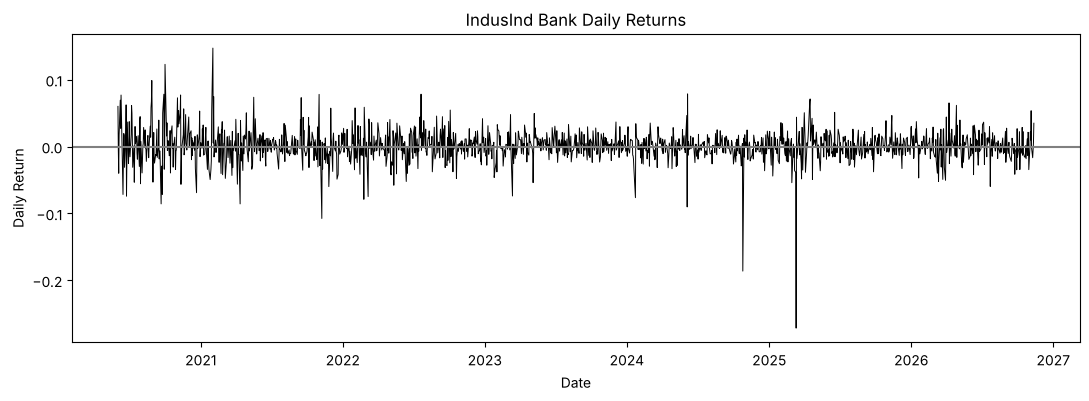

In [6]:
# [T2] daily returns plot
plt.figure(figsize=(13, 4))
plt.plot(returns, color="black", linewidth=0.7)
plt.axhline(0, color="grey")
plt.title("IndusInd Bank Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.show()

In [7]:
# [T2] rolling historical volatility
historical_vols = {}
for window in windows:
    historical_vols[window] = returns.shift(1).rolling(window).std()

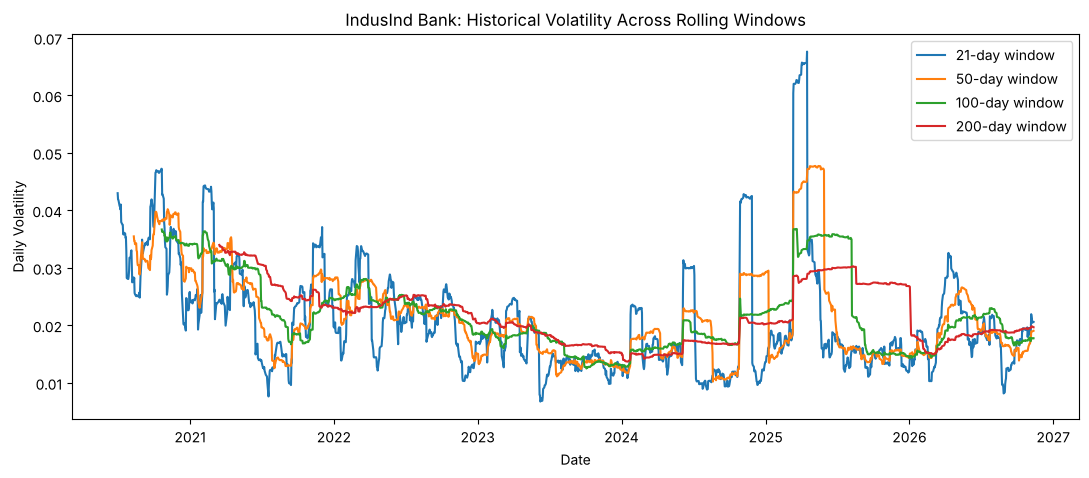

In [8]:
# [T2] rolling historical volatility plot
plt.figure(figsize=(13, 5))
for window in windows:
    plt.plot(historical_vols[window], label=f"{window}-day window")
plt.title("IndusInd Bank: Historical Volatility Across Rolling Windows")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

In [9]:
# [T2] EWMA volatility
ewma_var = returns.shift(1).pow(2).ewm(alpha=1 - lam, adjust=False).mean()
ewma_vol = np.sqrt(ewma_var)

In [10]:
# [T2] EWMA lambda by maximum likelihood
def ewma_neg_loglik(l):
    v = returns.shift(1).pow(2).ewm(alpha=1 - l, adjust=False).mean()
    v, r = v.iloc[1:], returns.iloc[1:]
    return np.sum(np.log(v) + r**2 / v)

opt = minimize_scalar(ewma_neg_loglik, bounds=(0.80, 0.999), method="bounded")
lam_mle = opt.x
ewma_vol_mle = np.sqrt(returns.shift(1).pow(2).ewm(alpha=1 - lam_mle, adjust=False).mean())

print("MLE lambda:", round(lam_mle, 4))
print("Neg log-lik at 0.94:", round(ewma_neg_loglik(lam), 2), "| at MLE:", round(ewma_neg_loglik(lam_mle), 2))

MLE lambda: 0.8756
Neg log-lik at 0.94: -10429.01 | at MLE: -10470.74


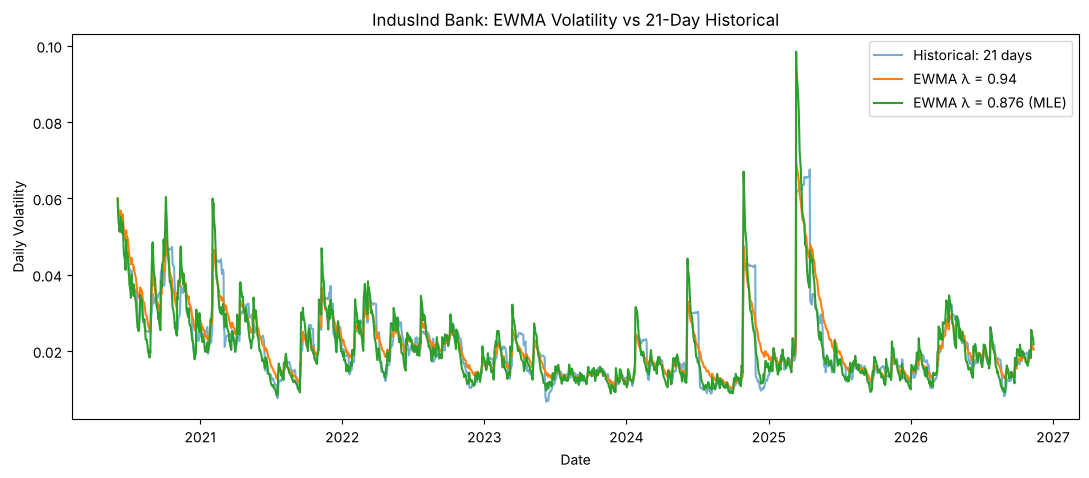

In [11]:
# [T2] EWMA plot
plt.figure(figsize=(13, 5))
plt.plot(historical_vols[21], label="Historical: 21 days", alpha=0.6)
plt.plot(ewma_vol, label=f"EWMA λ = {lam}")
plt.plot(ewma_vol_mle, label=f"EWMA λ = {lam_mle:.3f} (MLE)")
plt.title("IndusInd Bank: EWMA Volatility vs 21-Day Historical")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

In [12]:
# [T2] ARCH LM test
arch_test = het_arch(returns * 100, nlags=12)
print("LM statistic:", round(arch_test[0], 2))
print("LM p-value:", arch_test[1])

LM statistic: 9.72
LM p-value: 0.6407396952057587


/usr/local/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [13]:
# [T2] ARCH LM test robustness
lo, hi = returns.quantile([0.01, 0.99])
returns_w = returns.clip(lower=lo, upper=hi)

rows = []
for lags in [1, 5, 12]:
    raw = het_arch(returns * 100, nlags=lags)
    win = het_arch(returns_w * 100, nlags=lags)
    rows.append([lags, raw[0], raw[1], win[0], win[1]])

print(pd.DataFrame(rows, columns=["Lags", "LM (raw)", "p (raw)", "LM (winsorized)", "p (winsorized)"]).round(4).to_string(index=False))
print(f"Winsorization bounds: {lo:.4f} to {hi:.4f} | days clipped: {(returns != returns_w).sum()}")

 Lags  LM (raw)  p (raw)  LM (winsorized)  p (winsorized)
    1    5.2281   0.0222          80.8520             0.0
    5    8.3588   0.1375         131.7280             0.0
   12    9.7174   0.6407         135.4753             0.0
Winsorization bounds: -0.0580 to 0.0673 | days clipped: 32


/usr/local/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [14]:
# [T2] GARCH(1,1) normal
garch_model = arch_model(
    returns * 100,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=False
)
garch_res = garch_model.fit(disp="off")
garch_vol = garch_res.conditional_volatility / 100

print(garch_res.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:          INDUSINDBK.NS   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3486.49
Distribution:                  Normal   AIC:                           6980.97
Method:            Maximum Likelihood   BIC:                           7002.48
                                        No. Observations:                 1597
Date:                Sat, Nov 14 2026   Df Residuals:                     1596
Time:                        10:14:17   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1260  5.595e-02      2.251  2.437e-02 [1.629e-0

In [15]:
# [T2] GARCH(1,1) persistence
omega = garch_res.params["omega"]
alpha = garch_res.params["alpha[1]"]
beta = garch_res.params["beta[1]"]
persistence = alpha + beta

print("Alpha:", round(alpha, 4), "| Beta:", round(beta, 4), "| Persistence:", round(persistence, 4))
print("Half-life (days):", round(np.log(0.5) / np.log(persistence), 1))
print("Long-run daily vol:", round(np.sqrt(omega / (1 - persistence)) / 100, 4))

Alpha: 0.2772 | Beta: 0.6522 | Persistence: 0.9295
Half-life (days): 9.5
Long-run daily vol: 0.0299


In [16]:
# [T2] GARCH extensions
garch_t_res = arch_model(
    returns * 100, mean="Constant", vol="GARCH",
    p=1, q=1, dist="t", rescale=False
).fit(disp="off")

gjr_t_res = arch_model(
    returns * 100, mean="Constant", vol="GARCH",
    p=1, o=1, q=1, dist="t", rescale=False
).fit(disp="off")

garch_t_vol = garch_t_res.conditional_volatility / 100
gjr_t_vol = gjr_t_res.conditional_volatility / 100

print(garch_t_res.summary())
print(gjr_t_res.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                INDUSINDBK.NS   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3351.92
Distribution:      Standardized Student's t   AIC:                           6713.84
Method:                  Maximum Likelihood   BIC:                           6740.72
                                              No. Observations:                 1597
Date:                      Sat, Nov 14 2026   Df Residuals:                     1596
Time:                              10:14:17   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu     

In [17]:
# [T2] GARCH model comparison
def garch_summary(name, res):
    p = res.params
    gamma = p.get("gamma[1]", 0.0)
    pers = p["alpha[1]"] + p["beta[1]"] + gamma / 2
    vol = res.conditional_volatility / 100
    return {
        "Model": name,
        "Log-lik": res.loglikelihood,
        "AIC": res.aic,
        "BIC": res.bic,
        "alpha": p["alpha[1]"],
        "gamma": gamma,
        "beta": p["beta[1]"],
        "nu": p.get("nu", np.nan),
        "Persistence": pers,
        "Half-life (days)": np.log(0.5) / np.log(pers),
        "Long-run vol": np.sqrt(p["omega"] / (1 - pers)) / 100,
        "Peak vol": vol.max(),
        "Peak date": vol.idxmax().date(),
        "Latest vol": vol.iloc[-1],
        "Converged": res.convergence_flag == 0,
    }

garch_table = pd.DataFrame([
    garch_summary("GARCH(1,1)-N", garch_res),
    garch_summary("GARCH(1,1)-t", garch_t_res),
    garch_summary("GJR-GARCH(1,1)-t", gjr_t_res),
]).set_index("Model")

print(garch_table.round(4).T)

Model            GARCH(1,1)-N GARCH(1,1)-t GJR-GARCH(1,1)-t
Log-lik            -3486.4858    -3351.921       -3351.7049
AIC                 6980.9715     6713.842        6715.4098
BIC                 7002.4751    6740.7214        6747.6651
alpha                  0.2772       0.1646           0.1518
gamma                     0.0          0.0           0.0336
beta                   0.6522       0.7235           0.7196
nu                        NaN       4.1025           4.1009
Persistence            0.9295       0.8881           0.8883
Half-life (days)       9.4772       5.8391            5.852
Long-run vol           0.0299       0.0236           0.0237
Peak vol               0.1461       0.1131           0.1199
Peak date          2025-03-12   2025-03-12       2025-03-12
Latest vol             0.0223       0.0222           0.0219
Converged                True         True             True


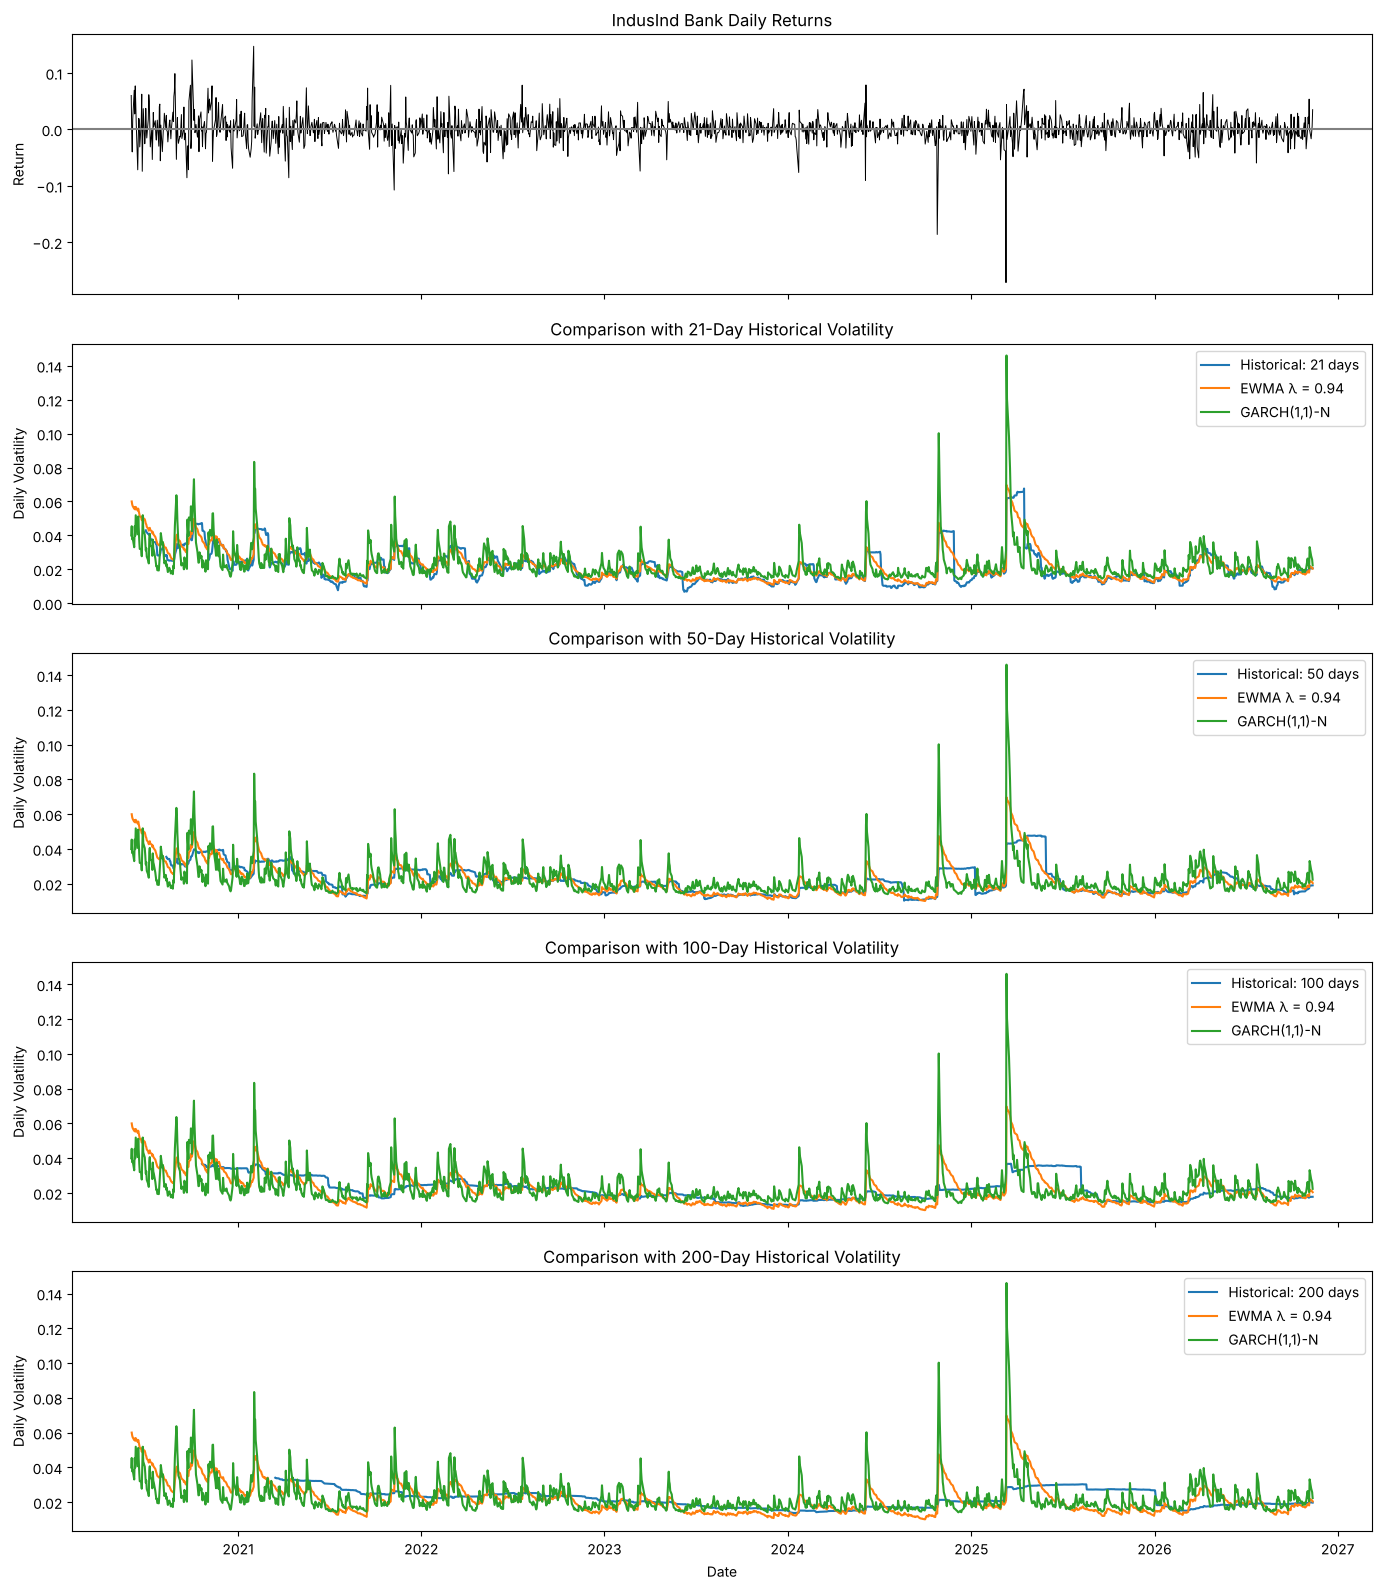

In [18]:
# [T2] volatility comparison (notebook layout)
fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)

axes[0].plot(returns, color="black", linewidth=0.7)
axes[0].axhline(0, color="grey")
axes[0].set_title("IndusInd Bank Daily Returns")
axes[0].set_ylabel("Return")

for ax, window in zip(axes[1:], windows):
    ax.plot(historical_vols[window], label=f"Historical: {window} days")
    ax.plot(ewma_vol, label=f"EWMA λ = {lam}")
    ax.plot(garch_vol, label="GARCH(1,1)-N")
    ax.set_title(f"Comparison with {window}-Day Historical Volatility")
    ax.set_ylabel("Daily Volatility")
    ax.legend()

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

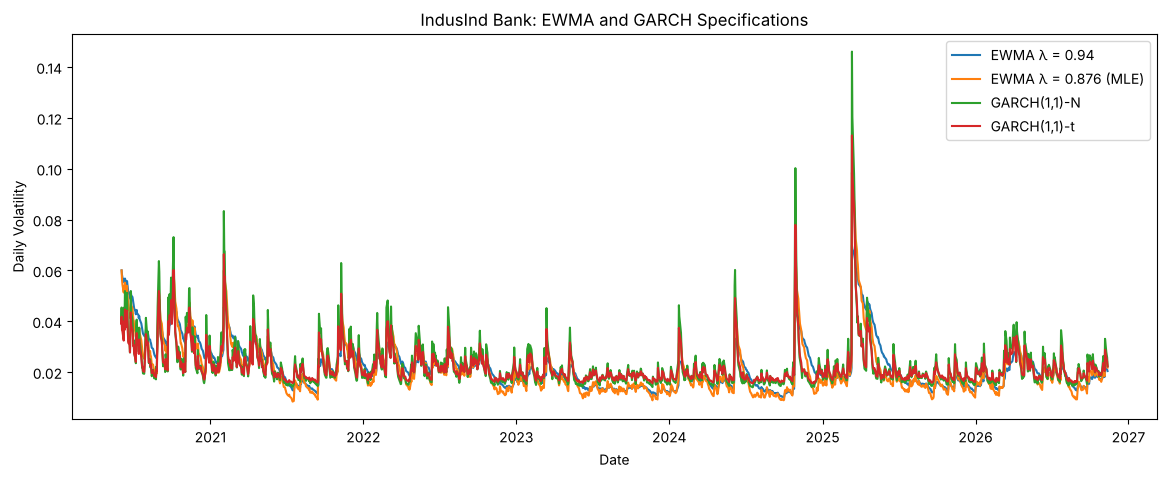

In [19]:
# [T2] EWMA and GARCH specifications compared
plt.figure(figsize=(14, 5))
plt.plot(ewma_vol, label=f"EWMA λ = {lam}")
plt.plot(ewma_vol_mle, label=f"EWMA λ = {lam_mle:.3f} (MLE)")
plt.plot(garch_vol, label="GARCH(1,1)-N")
plt.plot(garch_t_vol, label="GARCH(1,1)-t")
plt.title("IndusInd Bank: EWMA and GARCH Specifications")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

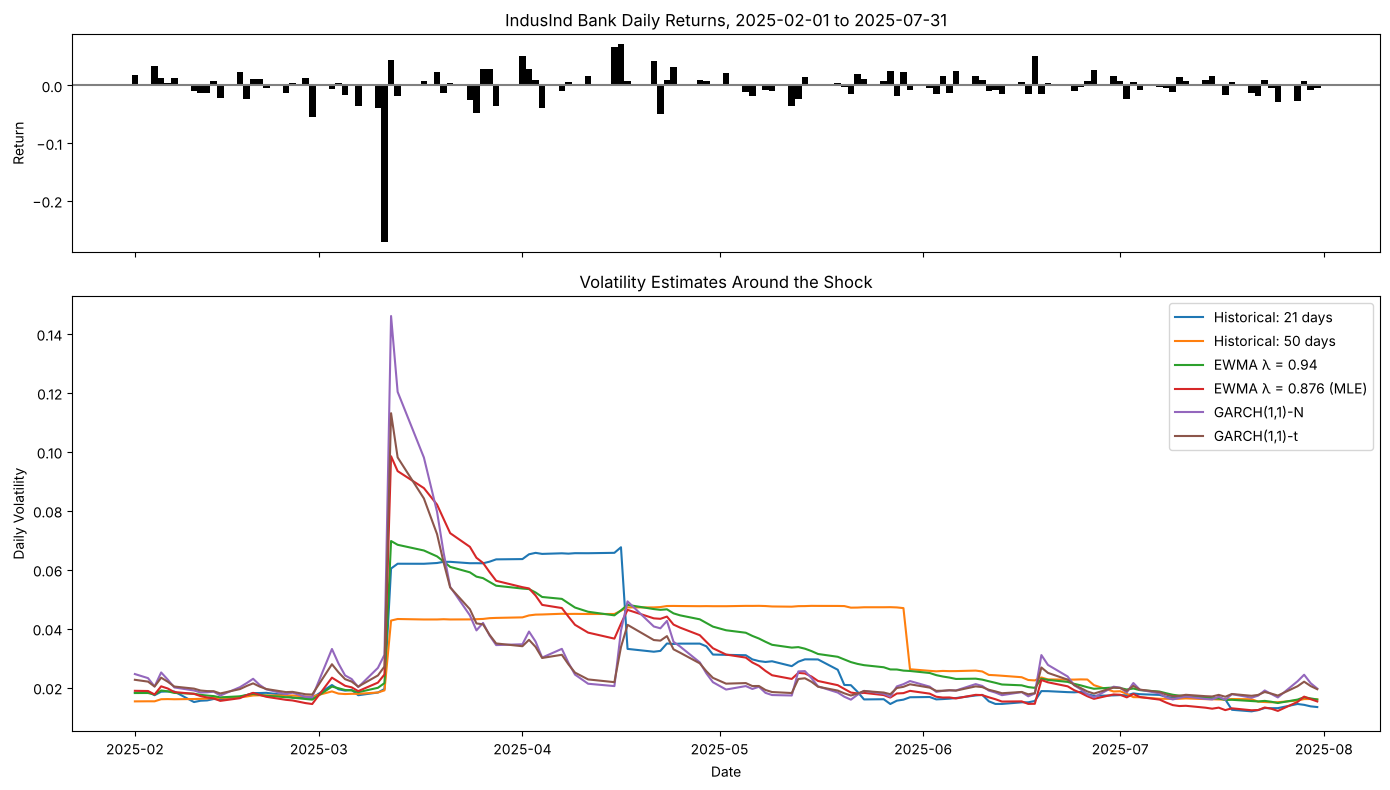

In [20]:
# [T2] crash window zoom
vol_estimators = {
    "Historical: 21 days": historical_vols[21],
    "Historical: 50 days": historical_vols[50],
    f"EWMA λ = {lam}": ewma_vol,
    f"EWMA λ = {lam_mle:.3f} (MLE)": ewma_vol_mle,
    "GARCH(1,1)-N": garch_vol,
    "GARCH(1,1)-t": garch_t_vol,
}

def plot_zoom(start, end):
    r = returns.loc[start:end]
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
    axes[0].bar(r.index, r, color="black", width=1)
    axes[0].axhline(0, color="grey")
    axes[0].set_title(f"IndusInd Bank Daily Returns, {start} to {end}")
    axes[0].set_ylabel("Return")
    for name, s in vol_estimators.items():
        axes[1].plot(s.loc[start:end], label=name)
    axes[1].set_title("Volatility Estimates Around the Shock")
    axes[1].set_ylabel("Daily Volatility")
    axes[1].set_xlabel("Date")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_zoom("2025-02-01", "2025-07-31")

In [21]:
# [T2] crash reaction table
key_dates = ["2025-03-11", "2025-03-12", "2025-04-16", "2025-04-17", "2025-05-30", "2025-07-31"]
reaction = pd.DataFrame({name: s.reindex(pd.to_datetime(key_dates)) for name, s in vol_estimators.items()}).T
reaction.columns = key_dates
print(reaction.round(4))

                      2025-03-11  2025-03-12  2025-04-16  2025-04-17  \
Historical: 21 days       0.0195      0.0604      0.0676      0.0331   
Historical: 50 days       0.0190      0.0427      0.0461      0.0472   
EWMA λ = 0.94             0.0215      0.0697      0.0462      0.0480   
EWMA λ = 0.876 (MLE)      0.0244      0.0985      0.0417      0.0464   
GARCH(1,1)-N              0.0311      0.1461      0.0393      0.0492   
GARCH(1,1)-t              0.0271      0.1131      0.0337      0.0413   

                      2025-05-30  2025-07-31  
Historical: 21 days       0.0167      0.0134  
Historical: 50 days       0.0262      0.0160  
EWMA λ = 0.94             0.0256      0.0159  
EWMA λ = 0.876 (MLE)      0.0189      0.0153  
GARCH(1,1)-N              0.0222      0.0197  
GARCH(1,1)-t              0.0211      0.0194  


## Task 3: Historical VaR

In [22]:
# [T3] historical VaR
var_levels = {"90%": 10, "95%": 5, "99%": 1}
hist_var = pd.Series({lvl: -np.percentile(var_returns, p, method="linear") for lvl, p in var_levels.items()})

print("Historical VaR (% loss):")
print((hist_var * 100).round(3).to_string())

Historical VaR (% loss):
90%    2.362
95%    3.444
99%    5.061


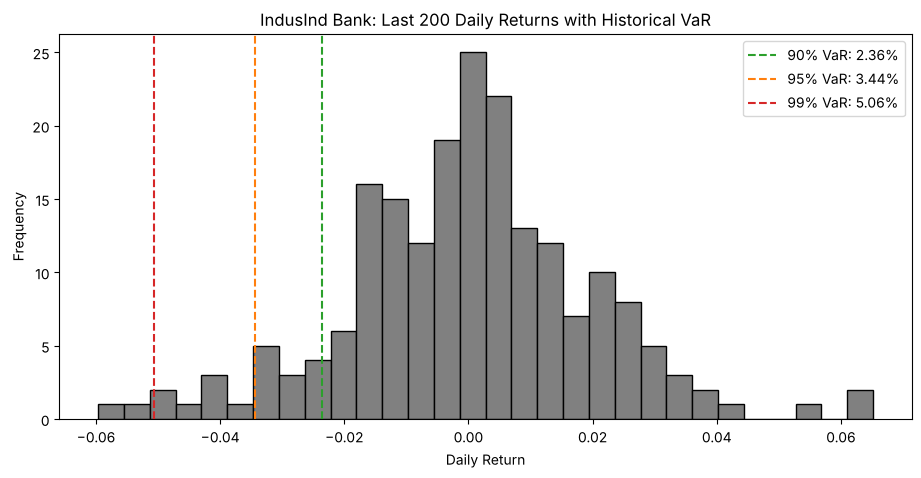

In [23]:
# [T3] historical VaR plot
plt.figure(figsize=(11, 5))
plt.hist(var_returns, bins=30, color="grey", edgecolor="black")
for (lvl, v), color in zip(hist_var.items(), ["tab:green", "tab:orange", "tab:red"]):
    plt.axvline(-v, color=color, linestyle="--", label=f"{lvl} VaR: {v * 100:.2f}%")
plt.title("IndusInd Bank: Last 200 Daily Returns with Historical VaR")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.legend()
plt.show()

## Task 4: Parametric VaR

This task computes one-day parametric (normal) VaR at 90%, 95% and 99% using two volatility estimates:

1. **Historical volatility** over a rolling window of up to 200 trading days.
2. **GARCH(1,1)** one-day-ahead volatility (EWMA is computed as a cross-check).

**Conventions (as in the sample notebook):** simple daily returns in decimal form, all volatilities daily (not annualised), VaR expressed as a positive loss fraction.

**Parametric VaR formula (normal distribution):**

$$
\text{VaR}_c = -\left(\mu_d - z_c\,\sigma_d\right) = z_c\,\sigma_d - \mu_d,
\qquad z_c = \Phi^{-1}(c)
$$

with $z_{0.90}=1.2816$, $z_{0.95}=1.6449$, $z_{0.99}=2.3263$.

### 4.1 Setup and parameters

In [24]:
# ticker, dates and price data come from Task 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm, skew, kurtosis, jarque_bera
from arch import arch_model
from statsmodels.stats.diagnostic import het_arch


VAR_SAMPLE  = 200               # most recent 200 daily returns (Tasks 3-6)
HV_WINDOW   = 200               # historical-vol window for Task 4 (must be <= 200)
lam         = 0.94              # EWMA decay factor (cross-check only)
conf_levels = [0.90, 0.95, 0.99]
USE_MEAN    = True              # True: VaR = z*sigma - mu ; False: zero-mean VaR = z*sigma

assert HV_WINDOW <= VAR_SAMPLE <= 200

### 4.2 Data and returns

In [25]:
# Same price data as Task 1 (zero-volume days removed); no second download
var_returns = returns.iloc[-VAR_SAMPLE:]        # most recent 200 trading days

print("Long sample (volatility models):", returns.index[0].date(), "to", returns.index[-1].date(), f"({len(returns)} returns)")
print("VaR sample (last 200 days)     :", var_returns.index[0].date(), "to", var_returns.index[-1].date(), f"({len(var_returns)} returns)")

Long sample (volatility models): 2020-06-02 to 2026-11-12 (1597 returns)
VaR sample (last 200 days)     : 2026-01-20 to 2026-11-12 (200 returns)


### 4.3 Volatility estimate 1 - Historical volatility

$$
\mu_d = \frac{1}{X}\sum_{i=1}^{X} r_{T-i+1},
\qquad
\sigma_d = \sqrt{\frac{1}{X-1}\sum_{i=1}^{X}(r_{T-i+1}-\mu_d)^2}
$$

computed over the most recent $X$ = `HV_WINDOW` returns. The mean $\mu_d$ is estimated over the **same window**.

**Choice of window (200 days).** The 200-day window uses the full VaR sample used in Tasks 3 and 5, so differences across methods come from the method itself rather than from different data. It is also the least noisy choice: the standard error of a volatility estimate is roughly $\sigma/\sqrt{2n}$ (about 5% of $\sigma$ for $n=200$, about 15% for $n=21$). The cost is slower reaction to a recent change in regime, which is why the GARCH estimate is used alongside it. The sensitivity table below shows how much the choice matters.

In [26]:
hv_sample = var_returns.iloc[-HV_WINDOW:]
mu_d       = hv_sample.mean()
sigma_hist = hv_sample.std()          # ddof=1, daily

print(f"Window: {HV_WINDOW} days  ({hv_sample.index[0].date()} to {hv_sample.index[-1].date()})")
print(f"Expected daily return mu_d : {mu_d:.6f}  ({mu_d*100:.4f}%)")
print(f"Historical daily vol sigma : {sigma_hist:.6f}  ({sigma_hist*100:.4f}%)")

# Sensitivity to window length (all within the 200-day VaR sample)
sens = pd.DataFrame({
    w: {"mu_d": var_returns.iloc[-w:].mean(), "sigma_d": var_returns.iloc[-w:].std()}
    for w in [21, 50, 100, 200]
}).T
sens.index.name = "window (days)"
sens

Window: 200 days  (2026-01-20 to 2026-11-12)
Expected daily return mu_d : 0.000106  (0.0106%)
Historical daily vol sigma : 0.019820  (1.9820%)


,mu_d,sigma_d
window (days),,
21,0.004413,0.021573
50,-0.001111,0.019730
100,0.000100,0.018105
200,0.000106,0.019820


### 4.4 Volatility estimate 2 - GARCH(1,1) one-day-ahead

First, Engle's ARCH LM test checks that volatility clustering exists (needed to justify a conditional-volatility model). Then GARCH(1,1) is fitted on the **long** return history (returns x 100 for numerical stability) and the **one-day-ahead** variance forecast for the next trading day is used:

$$
\sigma_{T+1}^2 = \omega + \alpha u_T^2 + \beta \sigma_T^2
$$

The forecast is divided by 100 to return to daily decimal volatility. The same $\mu_d$ from the historical-volatility window is used in the VaR formula, so the two rows of the table differ **only** through volatility.

In [27]:
arch_test = het_arch(returns * 100, nlags=12)
print(f"ARCH LM statistic: {arch_test[0]:.3f} | p-value: {arch_test[1]:.4g}")

model  = arch_model(returns * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="normal", rescale=False)
result = model.fit(disp="off")
print(result.summary())

omega = result.params["omega"]
alpha = result.params["alpha[1]"]
beta  = result.params["beta[1]"]
print(f"\nalpha = {alpha:.4f} | beta = {beta:.4f} | persistence (alpha+beta) = {alpha+beta:.4f}")

fc = result.forecast(horizon=1, reindex=False)
sigma_garch = np.sqrt(fc.variance.values[-1, 0]) / 100      # one-day-ahead daily vol, decimal
garch_vol   = result.conditional_volatility / 100            # in-sample series (for plotting)

print(f"\nGARCH one-day-ahead daily vol: {sigma_garch:.6f}  ({sigma_garch*100:.4f}%)")

ARCH LM statistic: 9.717 | p-value: 0.6407
                     Constant Mean - GARCH Model Results                      
Dep. Variable:          INDUSINDBK.NS   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3486.49
Distribution:                  Normal   AIC:                           6980.97
Method:            Maximum Likelihood   BIC:                           7002.48
                                        No. Observations:                 1597
Date:                Sat, Nov 14 2026   Df Residuals:                     1596
Time:                        10:14:19   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1260

/usr/local/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


**EWMA cross-check ($\lambda = 0.94$).** Not part of the six required estimates, but useful for interpretation:

$$
\sigma_{T+1}^2 = \lambda\sigma_T^2 + (1-\lambda) r_T^2
$$

In [28]:
ewma_var_path = returns.pow(2).ewm(alpha=1-lam, adjust=False).mean()   # value at T already includes r_T -> forecast for T+1
sigma_ewma = np.sqrt(ewma_var_path.iloc[-1])
ewma_vol = np.sqrt(returns.shift(1).pow(2).ewm(alpha=1-lam, adjust=False).mean())   # in-sample series as in sample notebook

print(f"EWMA one-day-ahead daily vol: {sigma_ewma:.6f}  ({sigma_ewma*100:.4f}%)")

EWMA one-day-ahead daily vol: 0.021533  (2.1533%)


### 4.5 Parametric VaR table (the six required estimates)

In [29]:
def parametric_var(mu, sigma, conf, use_mean=True):
    z = norm.ppf(conf)
    return z * sigma - (mu if use_mean else 0.0)     # positive = loss, as a fraction

z_vals = {c: norm.ppf(c) for c in conf_levels}
print("z-values:", {f"{int(c*100)}%": round(float(z), 4) for c, z in z_vals.items()})

vol_inputs = {
    f"Parametric - Historical Vol ({HV_WINDOW}d)": sigma_hist,
    "Parametric - GARCH(1,1)":                      sigma_garch,
}

var_table = pd.DataFrame(
    {f"{int(c*100)}% VaR": [parametric_var(mu_d, s, c, USE_MEAN) for s in vol_inputs.values()] for c in conf_levels},
    index=list(vol_inputs.keys()),
)
var_table.insert(0, "sigma_d (daily)", list(vol_inputs.values()))
var_table.insert(0, "mu_d (daily)", mu_d)

display_table = var_table.copy()
for col in display_table.columns:
    display_table[col] = display_table[col].map(lambda v: f"{v*100:.4f}%")
display_table

z-values: {'90%': 1.2816, '95%': 1.6449, '99%': 2.3263}


,mu_d (daily),sigma_d (daily),90% VaR,95% VaR,99% VaR
Parametric - Historical Vol (200d),0.0106%,1.9820%,2.5294%,3.2495%,4.6002%
"Parametric - GARCH(1,1)",0.0106%,2.6474%,3.3822%,4.3440%,6.1481%


#### Cross-checks (not part of the required table)

In [30]:
# (a) Zero-mean version, in case the class formula is VaR = z * sigma
zero_mean = pd.DataFrame(
    {f"{int(c*100)}% VaR": [parametric_var(mu_d, s, c, use_mean=False) for s in vol_inputs.values()] for c in conf_levels},
    index=list(vol_inputs.keys()),
)
print("Zero-mean version (VaR = z*sigma), in %:")
display((zero_mean * 100).round(4))

# (b) Other volatility estimates / windows at 95%
rows = {}
for w in [21, 50, 100, 200]:
    rows[f"Hist vol {w}d"] = parametric_var(var_returns.iloc[-w:].mean(), var_returns.iloc[-w:].std(), 0.95, USE_MEAN)
rows["EWMA (0.94)"] = parametric_var(mu_d, sigma_ewma, 0.95, USE_MEAN)
rows["GARCH(1,1)"]  = parametric_var(mu_d, sigma_garch, 0.95, USE_MEAN)
print("\n95% parametric VaR under alternative volatility inputs, in %:")
display((pd.Series(rows, name="95% VaR") * 100).round(4).to_frame())

# (c) How normal are the last 200 returns? (relevant to the normality assumption)
jb = jarque_bera(var_returns)
print(f"\nSkewness: {skew(var_returns):.3f} | Excess kurtosis: {kurtosis(var_returns):.3f} | Jarque-Bera p-value: {jb.pvalue:.4g}")

Zero-mean version (VaR = z*sigma), in %:


,90% VaR,95% VaR,99% VaR
Parametric - Historical Vol (200d),2.5400,3.2601,4.6108
"Parametric - GARCH(1,1)",3.3927,4.3545,6.1587



95% parametric VaR under alternative volatility inputs, in %:


,95% VaR
Hist vol 21d,3.1071
Hist vol 50d,3.3563
Hist vol 100d,2.9680
Hist vol 200d,3.2495
EWMA (0.94),3.5313
"GARCH(1,1)",4.3440



Skewness: -0.006 | Excess kurtosis: 0.990 | Jarque-Bera p-value: 0.01677


### 4.6 Plots

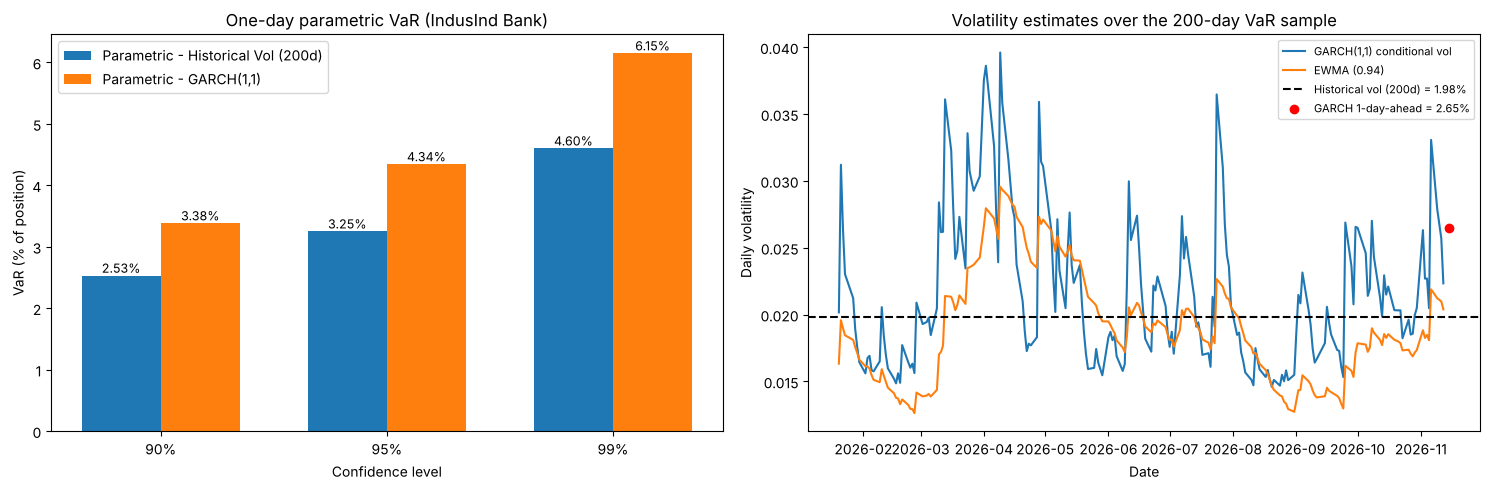

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: VaR by confidence level and volatility measure
x = np.arange(len(conf_levels)); width = 0.35
for i, (name, row) in enumerate(var_table.iterrows()):
    vals = [row[f"{int(c*100)}% VaR"] * 100 for c in conf_levels]
    bars = axes[0].bar(x + (i - 0.5) * width, vals, width, label=name)
    for b, v in zip(bars, vals):
        axes[0].text(b.get_x() + b.get_width()/2, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
axes[0].set_xticks(x); axes[0].set_xticklabels([f"{int(c*100)}%" for c in conf_levels])
axes[0].set_title("One-day parametric VaR (IndusInd Bank)")
axes[0].set_xlabel("Confidence level"); axes[0].set_ylabel("VaR (% of position)")
axes[0].legend()

# Right: volatility estimates over the VaR sample, with the inputs used
idx = var_returns.index
axes[1].plot(garch_vol.loc[idx], label="GARCH(1,1) conditional vol")
axes[1].plot(ewma_vol.loc[idx],  label="EWMA (0.94)")
axes[1].axhline(sigma_hist, color="black", linestyle="--", label=f"Historical vol ({HV_WINDOW}d) = {sigma_hist*100:.2f}%")
axes[1].scatter([idx[-1] + pd.Timedelta(days=3)], [sigma_garch], color="red", zorder=5, label=f"GARCH 1-day-ahead = {sigma_garch*100:.2f}%")
axes[1].set_title("Volatility estimates over the 200-day VaR sample")
axes[1].set_xlabel("Date"); axes[1].set_ylabel("Daily volatility")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("task4_parametric_var.png", dpi=150)
plt.show()

var_table.to_csv("task4_parametric_var_table.csv")

### 4.7 Auto-generated observations (numbers update when you re-run)

In [32]:
r95 = var_table["95% VaR"]
hv_name, g_name = list(vol_inputs.keys())
ratio = sigma_garch / sigma_hist

print(f"- Historical vol ({HV_WINDOW}d) = {sigma_hist*100:.3f}% vs GARCH one-day-ahead = {sigma_garch*100:.3f}%  -> GARCH/Historical = {ratio:.2f}x.")
if ratio > 1.05:
    print("  GARCH is higher: recent volatility is above the 200-day average, so the conditional model is flagging a more turbulent present than the equal-weighted window.")
elif ratio < 0.95:
    print("  GARCH is lower: recent volatility has calmed relative to the 200-day average, which the equal-weighted window is slow to reflect.")
else:
    print("  The two are close: recent volatility is near its 200-day average.")
print(f"- 95% VaR: Historical = {r95[hv_name]*100:.3f}%, GARCH = {r95[g_name]*100:.3f}% (difference {abs(r95[g_name]-r95[hv_name])*100:.3f} pp).")
print(f"- Going from 90% to 99% scales VaR by roughly {z_vals[0.99]/z_vals[0.90]:.2f}x (ratio of z-values) when the mean is small.")
print(f"- Mean effect: mu_d = {mu_d*100:.4f}% per day shifts every VaR by {-mu_d*100:+.4f} pp (small next to z*sigma).")
print(f"- GARCH persistence alpha+beta = {alpha+beta:.3f}; EWMA 1-day-ahead vol = {sigma_ewma*100:.3f}%.")
print(f"- Excess kurtosis of the 200 returns = {kurtosis(var_returns):.2f} (0 for a normal): values well above 0 mean fat tails, so the normal 99% VaR is the most likely to understate risk.")

- Historical vol (200d) = 1.982% vs GARCH one-day-ahead = 2.647%  -> GARCH/Historical = 1.34x.
  GARCH is higher: recent volatility is above the 200-day average, so the conditional model is flagging a more turbulent present than the equal-weighted window.
- 95% VaR: Historical = 3.249%, GARCH = 4.344% (difference 1.094 pp).
- Going from 90% to 99% scales VaR by roughly 1.82x (ratio of z-values) when the mean is small.
- Mean effect: mu_d = 0.0106% per day shifts every VaR by -0.0106 pp (small next to z*sigma).
- GARCH persistence alpha+beta = 0.929; EWMA 1-day-ahead vol = 2.153%.
- Excess kurtosis of the 200 returns = 0.99 (0 for a normal): values well above 0 mean fat tails, so the normal 99% VaR is the most likely to understate risk.


## Task 5: Monte Carlo Value at Risk (VaR)

This section estimates **one-day VaR at 90%, 95% and 99%** by Monte Carlo simulation, using the model

$$
R_{t+1}=\mu_d+\sigma_d Z
$$

where $\mu_d$ and $\sigma_d$ are the **daily** mean and standard deviation of the **most recent 200 daily simple returns**, and $Z$ is a random draw from a **standardised** (mean 0, variance 1) probability distribution.

**Conventions (same as the sample notebook):** simple daily returns in decimal form, daily (not annualised) volatility, VaR reported as a **positive loss**, e.g. 0.025 = a 2.5% loss.

**Plan of this section**
1. Setup, data and the 200-day VaR sample
2. Historical parameters $\mu_d,\sigma_d$ and a look at the return distribution
3. Choice and parameterisation of the distribution for $Z$
4. Simulation (10,000+ draws) and Monte Carlo VaR
5. Comparison with Historical and Parametric VaR
6. Robustness: degrees of freedom, simulation error
7. Report-ready summary, justification, advantages and limitations

### 5.1 Setup and data

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

# ---------- inputs (ticker, dates and data from Task 1) ----------

var_window = 200                       # most recent 200 trading days of returns
conf_levels = [0.90, 0.95, 0.99]
n_sims     = 100_000                   # >= 10,000 required
seed       = 42                        # reproducibility

pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

In [34]:
# Same price data as Task 1; only the last 200 returns are used for VaR
ret200 = returns.iloc[-var_window:]

print(f"Long sample : {returns.index[0].date()} -> {returns.index[-1].date()}  ({len(returns)} returns)")
print(f"VaR sample  : {ret200.index[0].date()} -> {ret200.index[-1].date()}  ({len(ret200)} returns)")
assert len(ret200) == var_window, "Not enough data for a 200-day sample"
assert ret200.isna().sum() == 0

Long sample : 2020-06-02 -> 2026-11-12  (1597 returns)
VaR sample  : 2026-01-20 -> 2026-11-12  (200 returns)


### 5.2 Historical parameters from the 200-day sample

$$
\mu_d=\frac1n\sum_{i=1}^{n} r_i,\qquad
\sigma_d=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(r_i-\mu_d)^2},\qquad n=200
$$

The sample standard deviation (denominator $n-1$) is used, consistent with the pandas `.std()` calls in the sample notebook. Before choosing a distribution for $Z$, we check whether the 200 returns look normal: skewness, excess kurtosis, the Jarque–Bera test and a Q–Q plot.

In [35]:
mu_d    = ret200.mean()
sigma_d = ret200.std(ddof=1)

skew      = stats.skew(ret200, bias=False)
ex_kurt   = stats.kurtosis(ret200, fisher=True, bias=False)   # excess kurtosis (normal = 0)
jb_stat, jb_p = stats.jarque_bera(ret200)

params = pd.Series({
    "n (observations)"        : len(ret200),
    "Mean return mu_d"        : mu_d,
    "Daily volatility sigma_d": sigma_d,
    "Minimum daily return"    : ret200.min(),
    "Maximum daily return"    : ret200.max(),
    "Skewness"                : skew,
    "Excess kurtosis"         : ex_kurt,
    "Jarque-Bera statistic"   : jb_stat,
    "Jarque-Bera p-value"     : jb_p,
})
params

n (observations)           200.000000
Mean return mu_d             0.000106
Daily volatility sigma_d     0.019820
Minimum daily return        -0.059665
Maximum daily return         0.065176
Skewness                    -0.006206
Excess kurtosis              1.046312
Jarque-Bera statistic        8.176783
Jarque-Bera p-value          0.016766
dtype: float64

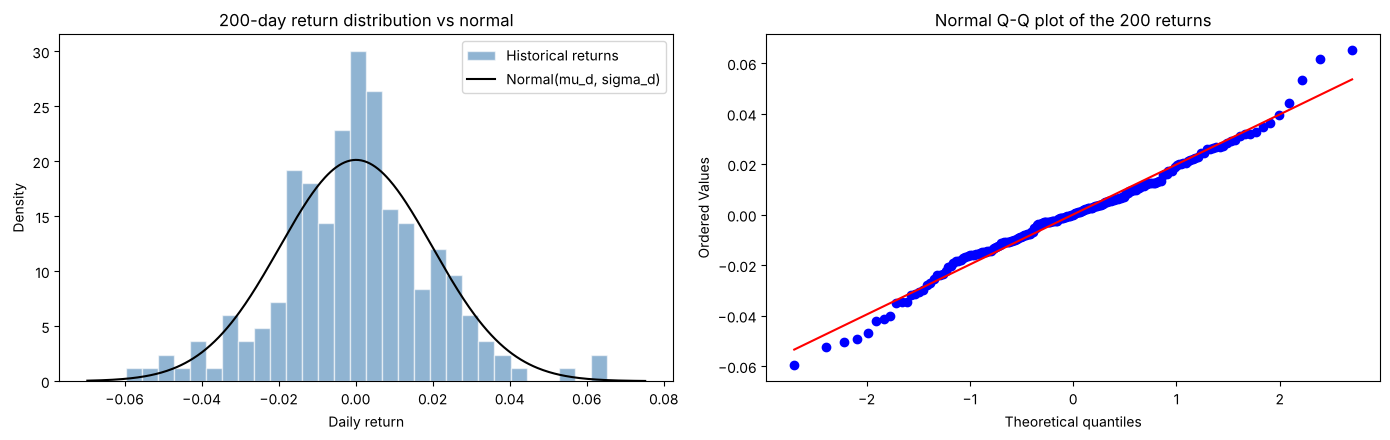

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# histogram vs fitted normal
ax[0].hist(ret200, bins=30, density=True, alpha=0.6, color="steelblue", edgecolor="white", label="Historical returns")
xs = np.linspace(ret200.min() - 0.01, ret200.max() + 0.01, 400)
ax[0].plot(xs, stats.norm.pdf(xs, mu_d, sigma_d), "k", lw=1.5, label="Normal(mu_d, sigma_d)")
ax[0].set_title("200-day return distribution vs normal")
ax[0].set_xlabel("Daily return"); ax[0].set_ylabel("Density"); ax[0].legend()

# Q-Q plot vs normal
stats.probplot(ret200, dist="norm", plot=ax[1])
ax[1].set_title("Normal Q-Q plot of the 200 returns")
plt.tight_layout(); plt.show()

### 5.3 Choice of distribution for $Z$ and its parameterisation

**Choice: Student-t distribution.** Daily bank-stock returns are typically **fat-tailed** (positive excess kurtosis): extreme days occur more often than a normal distribution allows. A Student-t with a small number of degrees of freedom $\nu$ captures this. The normal distribution is also simulated below as a benchmark, so the effect of the distributional assumption can be isolated.

**Appropriate parameterisation (important).** A raw Student-t variable $T_\nu$ has variance $\nu/(\nu-2)$ (for $\nu>2$), not 1. If $T_\nu$ were plugged directly into $R=\mu_d+\sigma_dZ$, the simulated volatility would be *larger* than the $\sigma_d$ estimated from the data. The model therefore uses the **standardised** t variable

$$
Z=\frac{T_\nu}{\sqrt{\nu/(\nu-2)}},\qquad E[Z]=0,\quad \mathrm{Var}[Z]=1,
$$

so that $\mu_d$ and $\sigma_d$ really are the mean and standard deviation of the simulated returns, and only the **shape** (tail heaviness) is governed by $\nu$.

**Estimating $\nu$.** Two estimates are computed from the 200 returns:
- *Maximum likelihood* fit of a location-scale Student-t (`scipy.stats.t.fit`).
- *Method of moments* from excess kurtosis, using $\text{excess kurtosis}=\dfrac{6}{\nu-4}$ for $\nu>4$, i.e. $\nu=4+6/\text{excess kurtosis}$.

The MLE is used as the main estimate. Since $\nu$ must exceed 2 for the variance to exist (and is poorly identified with only 200 points), it is restricted to the range **[3, 30]**; above about 30 the t is practically indistinguishable from the normal. Section 6 shows how sensitive VaR is to this choice.

In [37]:
# --- maximum likelihood estimate of nu (fit on returns in %, for numerical stability) ---
nu_mle, loc_mle, scale_mle = stats.t.fit(ret200 * 100)

# --- method-of-moments estimate from excess kurtosis (needs excess kurtosis > 0) ---
nu_mom = 4 + 6 / ex_kurt if ex_kurt > 0 else np.inf

nu_lo, nu_hi = 3.0, 30.0
nu = float(np.clip(nu_mle, nu_lo, nu_hi))

print(f"nu (MLE)                  : {nu_mle:8.2f}")
print(f"nu (kurtosis, moments)    : {nu_mom:8.2f}")
print(f"nu USED in the simulation : {nu:8.2f}", end="")
print("   <- MLE value was clipped to [3, 30]" if nu != nu_mle else "")

# standardisation constant: Var(T_nu) = nu/(nu-2)
t_std_const = np.sqrt(nu / (nu - 2))
print(f"Var(T_nu) = {nu/(nu-2):.4f}  -> divide draws by {t_std_const:.4f} so that Var(Z) = 1")

nu (MLE)                  :     5.61
nu (kurtosis, moments)    :     9.73
nu USED in the simulation :     5.61
Var(T_nu) = 1.5541  -> divide draws by 1.2466 so that Var(Z) = 1


### 5.4 Monte Carlo simulation and VaR

**Procedure**
1. $\mu_d,\sigma_d$ from the 200 historical returns (Section 2).
2. $Z$ = standardised Student-t($\nu$) (Section 3).
3. Generate `n_sims` = 100,000 simulated next-day returns $R_{t+1}=\mu_d+\sigma_dZ$ (the lab requires at least 10,000; more draws reduce simulation noise in the 1% tail).
4. VaR = minus the 10th, 5th and 1st percentile of the simulated returns (positive loss).

A fixed random seed makes the results reproducible.

In [38]:
def draw_Z(dist, n, rng, nu=None):
    """Standardised draws (mean 0, variance 1)."""
    if dist == "t":
        return rng.standard_t(nu, size=n) / np.sqrt(nu / (nu - 2))
    if dist == "normal":
        return rng.standard_normal(n)
    raise ValueError(dist)

def mc_var(mu, sigma, dist, n, rng, nu=None, conf=conf_levels):
    """Simulate R = mu + sigma*Z and return (VaR dict as positive losses, simulated returns)."""
    sim = mu + sigma * draw_Z(dist, n, rng, nu)
    var = {c: -np.percentile(sim, 100 * (1 - c)) for c in conf}
    return var, sim

rng = np.random.default_rng(seed)
var_t, sim_t = mc_var(mu_d, sigma_d, "t", n_sims, rng, nu=nu)

rng = np.random.default_rng(seed)
var_n, sim_n = mc_var(mu_d, sigma_d, "normal", n_sims, rng)

# sanity checks: the simulated sample must reproduce the target mean / std
print(f"Student-t sim : mean = {sim_t.mean():.6f} (target {mu_d:.6f}),  std = {sim_t.std(ddof=1):.6f} (target {sigma_d:.6f}),  "
      f"excess kurtosis = {stats.kurtosis(sim_t):.2f}")
print(f"Normal sim    : mean = {sim_n.mean():.6f},  std = {sim_n.std(ddof=1):.6f},  excess kurtosis = {stats.kurtosis(sim_n):.2f}")

Student-t sim : mean = 0.000081 (target 0.000106),  std = 0.019789 (target 0.019820),  excess kurtosis = 2.98
Normal sim    : mean = 0.000022,  std = 0.019893,  excess kurtosis = 0.02


In [39]:
labels = [f"{int(c*100)}% VaR" for c in conf_levels]
pct    = [f"{int(100*(1-c))}th percentile" if c != 0.99 else "1st percentile" for c in conf_levels]
pct    = ["10th percentile", "5th percentile", "1st percentile"]

mc_table = pd.DataFrame({
    "Confidence level"             : [f"{int(c*100)}%" for c in conf_levels],
    "Percentile used"              : pct,
    "Simulated return at percentile": [-var_t[c] for c in conf_levels],
    "MC VaR (decimal)"             : [var_t[c] for c in conf_levels],
    "MC VaR (% loss)"              : [f"{100*var_t[c]:.3f}%" for c in conf_levels],
}).set_index("Confidence level")

print(f"Monte Carlo VaR - Student-t (nu = {nu:.2f}), {n_sims:,} simulations, mu_d = {mu_d:.6f}, sigma_d = {sigma_d:.6f}")
mc_table

Monte Carlo VaR - Student-t (nu = 5.61), 100,000 simulations, mu_d = 0.000106, sigma_d = 0.019820


,Percentile used,Simulated return at percentile,MC VaR (decimal),MC VaR (% loss)
Confidence level,,,,
90%,10th percentile,-0.022919,0.022919,2.292%
95%,5th percentile,-0.031073,0.031073,3.107%
99%,1st percentile,-0.051301,0.051301,5.130%


### 5.5 Comparison with Historical and Parametric VaR

To discuss differences from the other methods, the **reference** values below are recomputed from the same 200 returns:

- **Historical simulation:** minus the 10th/5th/1st percentile of the 200 observed returns (Task 3).
- **Parametric (normal), 200-day historical volatility:** $\text{VaR}=z_{c}\,\sigma-\mu$ with $z_c$ the standard normal quantile (Task 4). Here the 200-day window is used for the comparison. If you chose a different window in Task 4, change `hist_window` below and the comparison will use your choice.

Because the parametric normal VaR is the *analytical* counterpart of the normal Monte Carlo, the normal MC should match it up to simulation noise, which is a useful correctness check.

In [40]:
hist_window = 200      # <- change to the window you chose for Task 4 (<= 200)

# Historical simulation (Task 3)
var_hist = {c: -np.percentile(ret200, 100 * (1 - c)) for c in conf_levels}

# Parametric normal, historical volatility (Task 4): VaR = z*sigma - mu
mu_p    = ret200.iloc[-hist_window:].mean()
sigma_p = ret200.iloc[-hist_window:].std(ddof=1)
var_param = {c: stats.norm.ppf(c) * sigma_p - mu_p for c in conf_levels}

comparison = pd.DataFrame(
    {
        "Historical Simulation"               : var_hist,
        f"Parametric - Hist. Vol ({hist_window}d)": var_param,
        "Monte Carlo - Normal (benchmark)"    : var_n,
        f"Monte Carlo - Student-t (nu={nu:.1f})": var_t,
    }
).T
comparison.columns = ["90% VaR", "95% VaR", "99% VaR"]

print("VaR as a positive loss (decimal) and in %:")
display(comparison)
display((comparison * 100).round(3).astype(str) + "%")

VaR as a positive loss (decimal) and in %:


,90% VaR,95% VaR,99% VaR
Historical Simulation,0.023615,0.034440,0.050612
Parametric - Hist. Vol (200d),0.025294,0.032495,0.046002
Monte Carlo - Normal (benchmark),0.025456,0.032762,0.046342
Monte Carlo - Student-t (nu=5.6),0.022919,0.031073,0.051301


,90% VaR,95% VaR,99% VaR
Historical Simulation,2.362%,3.444%,5.061%
Parametric - Hist. Vol (200d),2.529%,3.249%,4.6%
Monte Carlo - Normal (benchmark),2.546%,3.276%,4.634%
Monte Carlo - Student-t (nu=5.6),2.292%,3.107%,5.13%


In [41]:
# correctness check: normal MC vs analytic normal VaR (same mu, sigma -> should agree up to MC noise)
analytic_same_params = {c: stats.norm.ppf(c) * sigma_d - mu_d for c in conf_levels}
chk = pd.DataFrame({"Normal MC": var_n, "Analytic normal": analytic_same_params})
chk["Abs. difference"] = (chk["Normal MC"] - chk["Analytic normal"]).abs()
chk.index = [f"{int(c*100)}%" for c in chk.index]
chk

,Normal MC,Analytic normal,Abs. difference
90%,0.025456,0.025294,0.000161
95%,0.032762,0.032495,0.000267
99%,0.046342,0.046002,0.000340


In [42]:
# data-driven reading of the comparison
print("MC Student-t VaR relative to the other methods (positive = MC higher):\n")
for c in conf_levels:
    for name, ref in [("Historical", var_hist), ("Parametric normal", var_param)]:
        d = var_t[c] - ref[c]
        print(f"  {int(c*100)}% VaR: MC t vs {name:<18}: {100*d:+.3f} pp  ({100*d/ref[c]:+.1f}%)")
    print()

MC Student-t VaR relative to the other methods (positive = MC higher):

  90% VaR: MC t vs Historical        : -0.070 pp  (-2.9%)
  90% VaR: MC t vs Parametric normal : -0.238 pp  (-9.4%)

  95% VaR: MC t vs Historical        : -0.337 pp  (-9.8%)
  95% VaR: MC t vs Parametric normal : -0.142 pp  (-4.4%)

  99% VaR: MC t vs Historical        : +0.069 pp  (+1.4%)
  99% VaR: MC t vs Parametric normal : +0.530 pp  (+11.5%)



### Visualisation of the simulated distribution and its tail

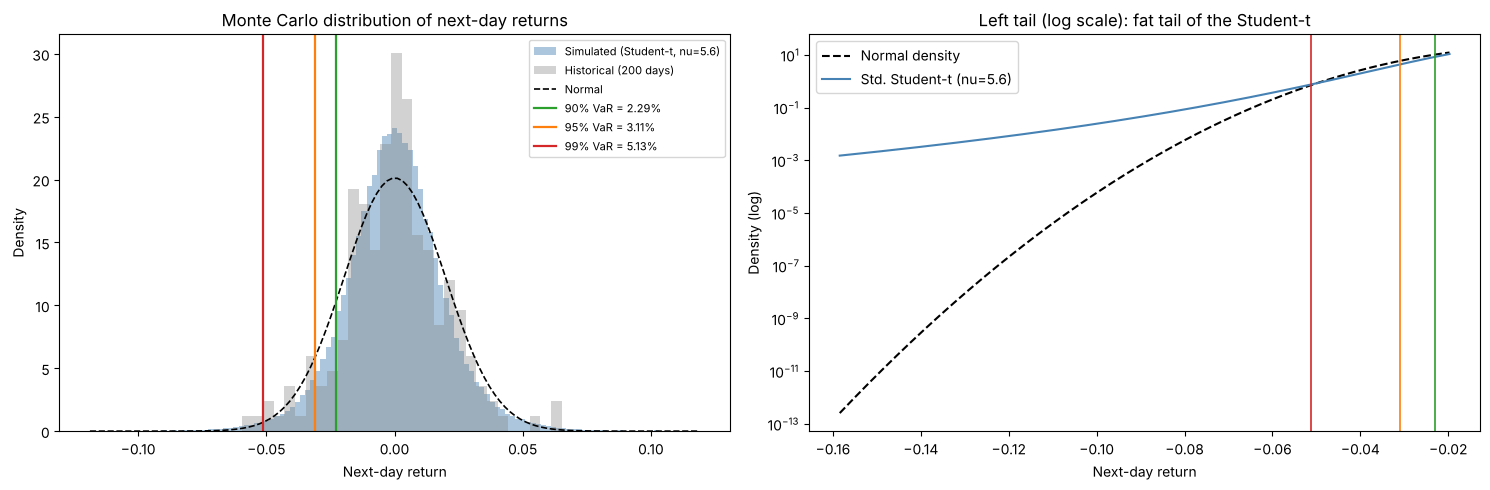

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
colors = {0.90: "tab:green", 0.95: "tab:orange", 0.99: "tab:red"}

# (a) full distribution
bins = np.linspace(-6 * sigma_d + mu_d, 6 * sigma_d + mu_d, 120)
ax[0].hist(sim_t, bins=bins, density=True, alpha=0.45, color="steelblue", label=f"Simulated (Student-t, nu={nu:.1f})")
ax[0].hist(ret200, bins=30, density=True, alpha=0.35, color="grey", label="Historical (200 days)")
ax[0].plot(bins, stats.norm.pdf(bins, mu_d, sigma_d), "k--", lw=1.2, label="Normal")
for c in conf_levels:
    ax[0].axvline(-var_t[c], color=colors[c], lw=1.6, label=f"{int(c*100)}% VaR = {100*var_t[c]:.2f}%")
ax[0].set_title("Monte Carlo distribution of next-day returns")
ax[0].set_xlabel("Next-day return"); ax[0].set_ylabel("Density"); ax[0].legend(fontsize=8)

# (b) left-tail zoom: Student-t vs normal
lo = min(sim_t.min(), sim_n.min())
xt = np.linspace(max(lo, mu_d - 8 * sigma_d), mu_d - 1.0 * sigma_d, 300)
ax[1].plot(xt, stats.norm.pdf(xt, mu_d, sigma_d), "k--", label="Normal density")
z = (xt - mu_d) / sigma_d
ax[1].plot(xt, stats.t.pdf(z * t_std_const, nu) * t_std_const / sigma_d, color="steelblue", label=f"Std. Student-t (nu={nu:.1f})")
for c in conf_levels:
    ax[1].axvline(-var_t[c], color=colors[c], lw=1.2)
ax[1].set_yscale("log")
ax[1].set_title("Left tail (log scale): fat tail of the Student-t")
ax[1].set_xlabel("Next-day return"); ax[1].set_ylabel("Density (log)"); ax[1].legend()
plt.tight_layout(); plt.show()

### 5.6 Robustness checks

#### 5.6a Sensitivity of Monte Carlo VaR to the degrees of freedom $\nu$
$\nu$ is estimated from only 200 observations and is therefore uncertain. The table shows VaR for a range of $\nu$ (with the same $\mu_d,\sigma_d$), together with the **theoretical** multiplier $q_c(\nu)$ = the standardised-t quantile, so that $\text{VaR}\approx q_c(\nu)\,\sigma_d-\mu_d$. The normal case ($\nu\to\infty$) is the last row.

In [44]:
nus = [3, 4, 5, 6, 8, 10, 15, 30]
rows = {}
for v in nus:
    rng = np.random.default_rng(seed)
    var_v, _ = mc_var(mu_d, sigma_d, "t", n_sims, rng, nu=v)
    rows[f"t, nu={v}"] = {**{f"MC VaR {int(c*100)}%": var_v[c] for c in conf_levels},
                          **{f"multiplier {int(c*100)}%": stats.t.ppf(c, v) / np.sqrt(v / (v - 2)) for c in conf_levels}}
rows["Normal (nu -> inf)"] = {**{f"MC VaR {int(c*100)}%": var_n[c] for c in conf_levels},
                              **{f"multiplier {int(c*100)}%": stats.norm.ppf(c) for c in conf_levels}}
sens = pd.DataFrame(rows).T
sens

,MC VaR 90%,MC VaR 95%,MC VaR 99%,multiplier 90%,multiplier 95%,multiplier 99%
"t, nu=3",0.018617,0.026891,0.051702,0.945552,1.358715,2.621576
"t, nu=4",0.021290,0.029656,0.052055,1.084141,1.507443,2.649492
"t, nu=5",0.022511,0.030717,0.051331,1.143215,1.560850,2.606464
"t, nu=6",0.023158,0.031291,0.051133,1.175556,1.586600,2.565978
"t, nu=8",0.023847,0.031751,0.049358,1.209678,1.610416,2.508407
"t, nu=10",0.024176,0.031989,0.048332,1.227318,1.621115,2.471991
"t, nu=15",0.024556,0.032240,0.047250,1.248036,1.632001,2.422777
"t, nu=30",0.025020,0.032543,0.046653,1.265981,1.639710,2.373940
Normal (nu -> inf),0.025456,0.032762,0.046342,1.281552,1.644854,2.326348


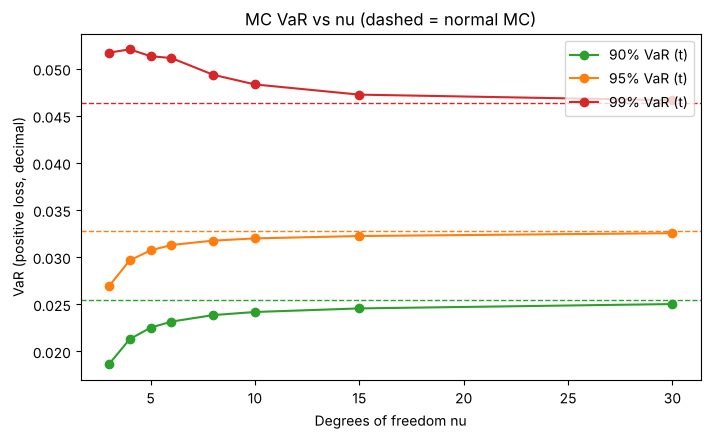

In [45]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for c in conf_levels:
    ax.plot(nus, [rows[f"t, nu={v}"][f"MC VaR {int(c*100)}%"] for v in nus], marker="o", color=colors[c], label=f"{int(c*100)}% VaR (t)")
    ax.axhline(var_n[c], color=colors[c], ls="--", lw=1)
ax.set_xlabel("Degrees of freedom nu"); ax.set_ylabel("VaR (positive loss, decimal)")
ax.set_title("MC VaR vs nu (dashed = normal MC)")
ax.legend(); plt.show()

#### 5.6b Simulation (sampling) error
Monte Carlo output changes slightly with the random seed. To quantify this, the whole simulation is repeated with 200 different seeds. The spread of the results measures the pure simulation noise (as opposed to the estimation uncertainty in $\mu_d,\sigma_d,\nu$ which is not captured here).

In [46]:
reps = 200
res = np.empty((reps, len(conf_levels)))
for k in range(reps):
    rng = np.random.default_rng(1000 + k)
    v, _ = mc_var(mu_d, sigma_d, "t", n_sims, rng, nu=nu)
    res[k] = [v[c] for c in conf_levels]

stab = pd.DataFrame({
    "Mean VaR"            : res.mean(axis=0),
    "Std. dev. across seeds": res.std(axis=0, ddof=1),
    "Min"                 : res.min(axis=0),
    "Max"                 : res.max(axis=0),
    "Std. dev. as % of VaR": 100 * res.std(axis=0, ddof=1) / res.mean(axis=0),
}, index=[f"{int(c*100)}%" for c in conf_levels])
print(f"{reps} repetitions x {n_sims:,} simulations each")
stab

200 repetitions x 100,000 simulations each


,Mean VaR,Std. dev. across seeds,Min,Max,Std. dev. as % of VaR
90%,0.022991,0.000115,0.022651,0.023276,0.499017
95%,0.031192,0.000172,0.030596,0.031549,0.552233
99%,0.051012,0.000397,0.049957,0.051988,0.778247


In [47]:
# how many simulations are 'enough'? 99% VaR vs. number of draws
sizes = [1_000, 5_000, 10_000, 50_000, 100_000, 500_000]
conv = {}
for n in sizes:
    vals = []
    for k in range(30):
        rng = np.random.default_rng(5000 + k)
        vals.append(mc_var(mu_d, sigma_d, "t", n, rng, nu=nu)[0][0.99])
    conv[n] = (np.mean(vals), np.std(vals, ddof=1))
conv = pd.DataFrame(conv, index=["Mean 99% VaR", "Std. dev. across seeds"]).T
conv.index.name = "Number of simulations"
conv

,Mean 99% VaR,Std. dev. across seeds
Number of simulations,,
1000,0.050662,0.005013
5000,0.051092,0.002203
10000,0.050990,0.001051
50000,0.050918,0.000590
100000,0.050913,0.000464
500000,0.051069,0.000185


## Task 6: VaR Comparison and Scenario Analysis

**Part A** collects the one-day VaR estimates from Tasks 3-5 into one table and compares them. **Part B** builds a two-dimensional scenario table for the 95% parametric VaR based on historical volatility (Task 4).

### 6.1 Setup

In [48]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats

# chart colours: fixed categorical order, one colour per method
C = {"hs": "#2a78d6", "ph": "#eb6834", "pg": "#1baf7a", "mc": "#eda100"}

### Part A: Comparison of VaR Methods

#### 6.2 Collect the Task 3-5 estimates

Each method uses the same 200 returns. They differ only in **how the loss distribution is built**:

| Method | Volatility input | Distribution of returns |
|---|---|---|
| Historical simulation (Task 3) | none (uses the returns directly) | the 200 observed returns |
| Parametric, historical volatility (Task 4) | 200-day sample std. dev. | normal |
| Parametric, GARCH(1,1) (Task 4) | one-day-ahead GARCH forecast | normal |
| Monte Carlo (Task 5) | 200-day sample std. dev. | standardised Student-t, $\nu$ by MLE |

Parametric VaR: $\text{VaR}_c = z_c\,\sigma_d - \mu_d$. The same $\mu_d$ (200-day mean) is used in every parametric and Monte Carlo row.

In [49]:
# Task 3: historical simulation (hist_var, keyed "90%", "95%", "99%")
hs_var = {c: hist_var[f"{int(c*100)}%"] for c in conf_levels}

# Task 4: parametric VaR table and volatility inputs
hv_name, g_name = list(vol_inputs.keys())
ph_var = {c: var_table.loc[hv_name, f"{int(c*100)}% VaR"] for c in conf_levels}
pg_var = {c: var_table.loc[g_name,  f"{int(c*100)}% VaR"] for c in conf_levels}
pe_var = {c: parametric_var(mu_d, sigma_ewma, c, USE_MEAN) for c in conf_levels}
garch_res = result                     # Task 4 GARCH(1,1) fit (used in the backtest)

# Task 5: Monte Carlo, Student-t (main) and normal (benchmark)
mc_t_var, mc_n_var = var_t, var_n

var_returns = returns.iloc[-var_window:]
print(f"mu_d = {mu_d:.6f} | sigma (200d) = {sigma_hist:.6f} | sigma GARCH = {sigma_garch:.6f} | "
      f"sigma EWMA = {sigma_ewma:.6f} | nu = {nu:.2f}")

mu_d = 0.000106 | sigma (200d) = 0.019820 | sigma GARCH = 0.026474 | sigma EWMA = 0.021533 | nu = 5.61


#### 6.3 Comparison table

The four required rows. For the EWMA/GARCH row, Task 4 used **GARCH(1,1)** as the main estimate; EWMA was only a cross-check, so it appears in the supplementary table below together with the normal Monte Carlo benchmark.

In [50]:
methods = {
    "Historical Simulation":                        hs_var,
    "Parametric - Historical Volatility (200d)":    ph_var,
    "Parametric - GARCH(1,1)":                      pg_var,
    f"Monte Carlo Simulation (Student-t, nu={nu:.1f})": mc_t_var,
}
cols = [f"{int(c*100)}% VaR" for c in conf_levels]
comparison = pd.DataFrame([[m[c] for c in conf_levels] for m in methods.values()],
                          index=list(methods.keys()), columns=cols)
comparison.index.name = "Method"

(comparison * 100).style.format("{:.3f}%").set_caption("One-day VaR, IndusInd Bank (% of position)")

,90% VaR,95% VaR,99% VaR
Method,,,
Historical Simulation,2.362%,3.444%,5.061%
Parametric - Historical Volatility (200d),2.529%,3.249%,4.600%
"Parametric - GARCH(1,1)",3.382%,4.344%,6.148%
"Monte Carlo Simulation (Student-t, nu=5.6)",2.292%,3.107%,5.130%


In [51]:
supplementary = pd.DataFrame(
    [[pe_var[c] for c in conf_levels], [mc_n_var[c] for c in conf_levels]],
    index=["Parametric - EWMA (0.94), cross-check", "Monte Carlo - Normal, benchmark"], columns=cols)
(supplementary * 100).style.format("{:.3f}%").set_caption("Supplementary estimates (not in the required table)")

,90% VaR,95% VaR,99% VaR
"Parametric - EWMA (0.94), cross-check",2.749%,3.531%,4.999%
"Monte Carlo - Normal, benchmark",2.546%,3.276%,4.634%


#### 6.4 Visual comparison and relative size

The table below the chart expresses every estimate relative to historical simulation, which makes no distributional assumption and is therefore a natural reference point.

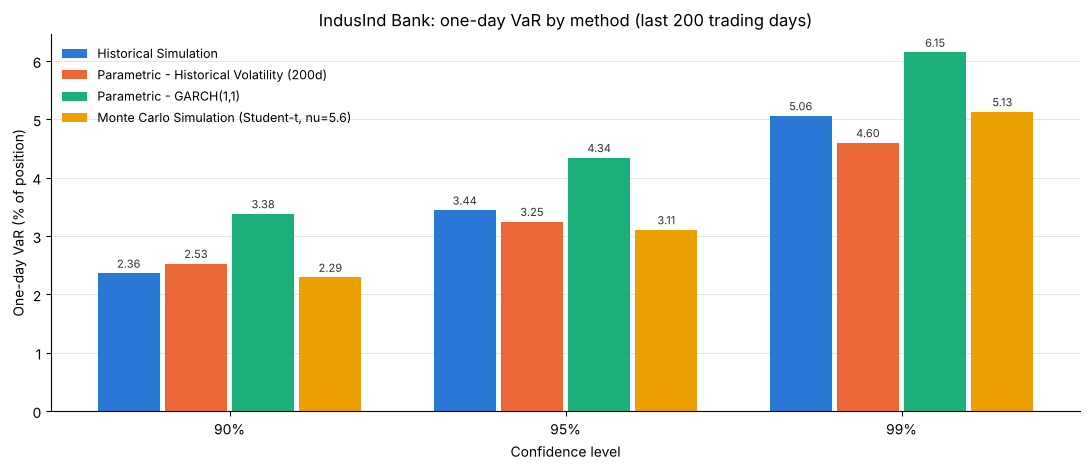

,90% VaR,95% VaR,99% VaR
Method,,,
Historical Simulation,1.00x,1.00x,1.00x
Parametric - Historical Volatility (200d),1.07x,0.94x,0.91x
"Parametric - GARCH(1,1)",1.43x,1.26x,1.21x
"Monte Carlo Simulation (Student-t, nu=5.6)",0.97x,0.90x,1.01x


In [52]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x, w = np.arange(len(conf_levels)), 0.2
for i, (name, key) in enumerate(zip(comparison.index, C)):
    vals = comparison.loc[name].values * 100
    bars = ax.bar(x + (i - 1.5) * w, vals, w * 0.92, color=C[key], label=name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color="#333333")
ax.set_xticks(x, [f"{int(c*100)}%" for c in conf_levels])
ax.set_xlabel("Confidence level"); ax.set_ylabel("One-day VaR (% of position)")
ax.set_title("IndusInd Bank: one-day VaR by method (last 200 trading days)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e1e0d9", lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("task6_var_comparison.png", dpi=150); plt.show()

ratio = comparison.div(comparison.loc["Historical Simulation"], axis=1)
ratio.style.format("{:.2f}x").set_caption("VaR relative to historical simulation")

#### 6.5 Why the estimates differ: implied multipliers and tail shape

Writing every estimate as $\text{VaR} = k\,\sigma_{200} - \mu_d$ gives an **implied multiplier** $k = (\text{VaR}+\mu_d)/\sigma_{200}$. For the normal model $k$ is just $z_c$. A $k$ above $z_c$ means the method sees a fatter left tail (or higher current volatility) than the normal model with 200-day volatility. This separates the two effects: the **volatility estimator** (GARCH vs 200-day) and the **distributional assumption** (empirical vs normal vs Student-t).

In [53]:
implied_k = (comparison + mu_d) / sigma_hist
implied_k.loc["Normal z-value (reference)"] = [stats.norm.ppf(c) for c in conf_levels]
display(implied_k.round(3))

r21 = var_returns.iloc[-21:]
facts = pd.Series({
    "Skewness (200d)":                         stats.skew(var_returns, bias=False),
    "Excess kurtosis (200d, normal = 0)":      stats.kurtosis(var_returns, bias=False),
    "Jarque-Bera p-value":                     stats.jarque_bera(var_returns).pvalue,
    "Worst daily return in sample":            var_returns.min(),
    "Std. dev. last 21 days":                  r21.std(),
    "Std. dev. 200 days":                      sigma_hist,
    "GARCH vol for 12 Nov (before that day's return)": garch_res.conditional_volatility.iloc[-1] / 100,
    "GARCH one-day-ahead vol (for 13 Nov)":    sigma_garch,
    "EWMA one-day-ahead vol":                  sigma_ewma,
    "GARCH long-run vol":                      np.sqrt(garch_res.params["omega"] / (1 - garch_res.params["alpha[1]"] - garch_res.params["beta[1]"])) / 100,
    "GARCH persistence (alpha + beta)":        garch_res.params["alpha[1]"] + garch_res.params["beta[1]"],
    "Last return (12 Nov 2026)":               var_returns.iloc[-1],
})
facts.to_frame("value").style.format("{:.4f}")

,90% VaR,95% VaR,99% VaR
Method,,,
Historical Simulation,1.197000,1.743000,2.559000
Parametric - Historical Volatility (200d),1.282000,1.645000,2.326000
"Parametric - GARCH(1,1)",1.712000,2.197000,3.107000
"Monte Carlo Simulation (Student-t, nu=5.6)",1.162000,1.573000,2.594000
Normal z-value (reference),1.282000,1.645000,2.326000


,value
Skewness (200d),-0.0062
"Excess kurtosis (200d, normal = 0)",1.0463
Jarque-Bera p-value,0.0168
Worst daily return in sample,-0.0597
Std. dev. last 21 days,0.0216
Std. dev. 200 days,0.0198
GARCH vol for 12 Nov (before that day's return),0.0223
GARCH one-day-ahead vol (for 13 Nov),0.0265
EWMA one-day-ahead vol,0.0215
GARCH long-run vol,0.0299


#### 6.6 Supplementary check: rolling one-day-ahead backtest

The comparison table alone cannot say which method is *right*. As supporting evidence, each method is run every day over the long sample using only the previous 200 returns, and the number of days on which the loss exceeded the VaR is counted. A good 95% VaR should be exceeded on about 5% of days. The Kupiec test checks whether the observed exceedance rate is consistent with the target ($p < 0.05$ means it is not).

Simplifications (so the check runs in seconds): GARCH uses the full-sample parameters with its one-step-ahead conditional volatility, and the Student-t row uses the analytic standardised-t quantile with the Task 5 $\nu$, which is what the Monte Carlo converges to. Both use information from the full sample, so this is indicative rather than a strict out-of-sample test.

In [54]:
def kupiec_p(n_exc, n, p):
    if n_exc == 0:
        return np.nan
    phat = n_exc / n
    lr = -2 * ((n - n_exc) * np.log((1 - p) / (1 - phat)) + n_exc * np.log(p / phat))
    return 1 - stats.chi2.cdf(lr, 1)

roll_mu  = returns.rolling(var_window).mean().shift(1)
roll_sd  = returns.rolling(var_window).std().shift(1)
garch_sd = garch_res.conditional_volatility / 100          # sigma_t uses information up to t-1
t_mult   = lambda c: stats.t.ppf(c, nu) / np.sqrt(nu / (nu - 2))

bt_rows = []
for c in conf_levels:
    forecasts = {
        "Historical Simulation":     -returns.rolling(var_window).quantile(1 - c).shift(1),
        "Parametric - Hist. Vol":    stats.norm.ppf(c) * roll_sd - roll_mu,
        "Parametric - GARCH(1,1)":   stats.norm.ppf(c) * garch_sd - roll_mu,
        "Monte Carlo (Student-t)":   t_mult(c) * roll_sd - roll_mu,
    }
    for name, f in forecasts.items():
        ok = f.notna()
        exc = (returns[ok] < -f[ok]).sum(); n = ok.sum()
        bt_rows.append({"Confidence": f"{int(c*100)}%", "Method": name, "Days": n,
                        "Exceedances": exc, "Rate": exc / n, "Target": 1 - c,
                        "Kupiec p-value": kupiec_p(exc, n, 1 - c)})

backtest = pd.DataFrame(bt_rows).set_index(["Confidence", "Method"])
backtest.style.format({"Rate": "{:.2%}", "Target": "{:.0%}", "Kupiec p-value": "{:.3f}"})

#### 6.7 Key numbers for the discussion (auto-generated)

In [55]:
lo = comparison.idxmin(); hi = comparison.idxmax()
for col in cols:
    print(f"- {col}: lowest = {lo[col]} ({comparison[col].min()*100:.3f}%), "
          f"highest = {hi[col]} ({comparison[col].max()*100:.3f}%), "
          f"spread = {(comparison[col].max()-comparison[col].min())*100:.3f} pp")
print(f"- GARCH vol / 200-day vol = {sigma_garch/sigma_hist:.2f}x, so the GARCH row is about "
      f"{(sigma_garch/sigma_hist-1)*100:.0f}% above the historical-volatility row at every level.")
print(f"- The last return in the sample ({var_returns.index[-1].date()}) was {var_returns.iloc[-1]*100:+.2f}%. GARCH reacts to its square, "
      f"so the forecast jumped from {garch_res.conditional_volatility.iloc[-1]:.2f}% to {sigma_garch*100:.2f}% even though the move was a gain.")
print(f"- Student-t vs normal (same mu, sigma): 90% {ratio.iloc[3,0]/ratio.iloc[1,0]:.2f}x, "
      f"95% {ratio.iloc[3,1]/ratio.iloc[1,1]:.2f}x, 99% {ratio.iloc[3,2]/ratio.iloc[1,2]:.2f}x "
      "-> fat tails lower VaR near the centre and raise it in the far tail.")
print(f"- Historical simulation vs normal: implied multiplier at 99% = {implied_k.iloc[0,2]:.2f} vs z = 2.33 "
      f"-> the empirical 1% tail is fatter than normal.")

- 90% VaR: lowest = Monte Carlo Simulation (Student-t, nu=5.6) (2.292%), highest = Parametric - GARCH(1,1) (3.382%), spread = 1.090 pp
- 95% VaR: lowest = Monte Carlo Simulation (Student-t, nu=5.6) (3.107%), highest = Parametric - GARCH(1,1) (4.344%), spread = 1.237 pp
- 99% VaR: lowest = Parametric - Historical Volatility (200d) (4.600%), highest = Parametric - GARCH(1,1) (6.148%), spread = 1.548 pp
- GARCH vol / 200-day vol = 1.34x, so the GARCH row is about 34% above the historical-volatility row at every level.
- The last return in the sample (2026-11-12) was +3.48%. GARCH reacts to its square, so the forecast jumped from 2.23% to 2.65% even though the move was a gain.
- Student-t vs normal (same mu, sigma): 90% 0.91x, 95% 0.96x, 99% 1.12x -> fat tails lower VaR near the centre and raise it in the far tail.
- Historical simulation vs normal: implied multiplier at 99% = 2.56 vs z = 2.33 -> the empirical 1% tail is fatter than normal.


### Part B: Parametric VaR Scenario Analysis

#### 6.8 Baseline and scenario grid

**Selected model:** parametric VaR with 200-day historical volatility (Task 4), at **95%**:

$$
\text{VaR}_{95\%} = 1.6449\,\sigma_d - \mu_d
$$

**Baseline:** $\mu_d$ and $\sigma_d$ from the 200-day sample.

**How the scenarios are defined**
- **Volatility** is changed **in proportion** to its baseline (multipliers from 0.5x to 3.5x). The range covers calm periods (the lowest 21-day volatility since 2020 was about 0.34x today's level, June 2023) and stress (about 3.4x during the March 2025 crash).
- **Expected return** is changed by **adding a shift** to the baseline, in percentage points per day (-2.0 to +2.0 pp). A proportional change is not useful here: the baseline mean is only 0.0106% a day, so even doubling it moves VaR by 0.01 pp, and a proportional change can never make a positive mean negative. The extreme shifts match the most extreme 21-day average returns since 2020 (about -2.1% a day in March 2025 and +2.1% a day in late 2020).

In [56]:
c_s       = 0.95
z95       = stats.norm.ppf(c_s)
mu_base   = mu_d
sig_base  = sigma_hist
var_base  = z95 * sig_base - mu_base

mu_shifts = np.array([-2.0, -1.0, -0.5, -0.25, 0.0, 0.25, 0.5, 1.0, 2.0]) / 100   # added to mu (decimal)
vol_mults = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 2.00, 3.00, 3.50])            # times sigma

# every combination, with the parametric formula
grid = pd.DataFrame(
    [[z95 * (sig_base * m) - (mu_base + s) for m in vol_mults] for s in mu_shifts],
    index=pd.Index([f"{s*100:+.2f} pp" for s in mu_shifts], name="Change in expected daily return"),
    columns=pd.Index([f"{m:.2f}x" for m in vol_mults], name="Volatility (x baseline)"),
)

print(f"Baseline mu_d = {mu_base:.6f} ({mu_base*100:.4f}%/day), sigma_d = {sig_base:.6f} ({sig_base*100:.4f}%/day)")
print(f"Task 4 95% VaR (historical vol)  = {ph_var[0.95]*100:.4f}%")
print(f"Baseline-Baseline cell of grid   = {grid.loc['+0.00 pp', '1.00x']*100:.4f}%")
assert np.isclose(grid.loc["+0.00 pp", "1.00x"], ph_var[0.95]), "baseline cell must reproduce Task 4"

Baseline mu_d = 0.000106 (0.0106%/day), sigma_d = 0.019820 (1.9820%/day)
Task 4 95% VaR (historical vol)  = 3.2495%
Baseline-Baseline cell of grid   = 3.2495%


#### 6.9 Scenario heatmap (95% one-day VaR)

Each cell is the 95% VaR (% of position) for one combination. Colours are centred on the baseline VaR: **orange = more risk than the baseline, blue = less risk**. The baseline cell is outlined. Row and column labels also show the actual $\mu_d$ and $\sigma_d$ used.

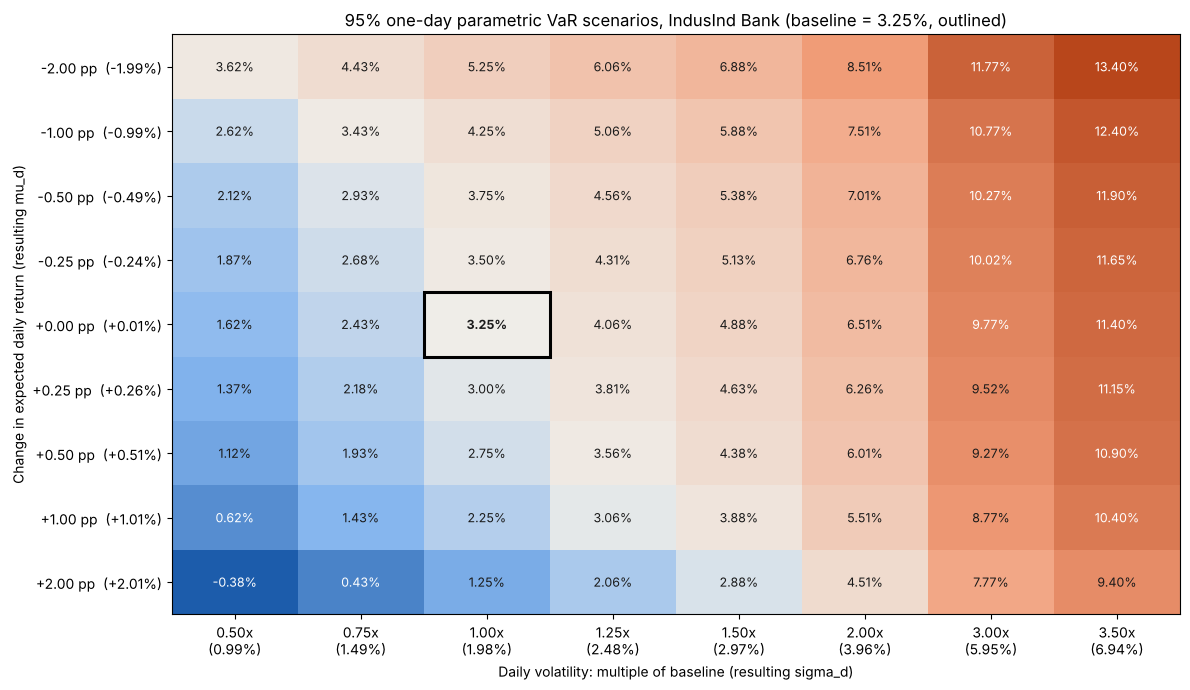

In [57]:
vals = grid.values * 100
cmap = LinearSegmentedColormap.from_list("risk", ["#1c5cab", "#86b6ef", "#efeee9", "#f3a07c", "#b8461b"])
norm = TwoSlopeNorm(vmin=vals.min(), vcenter=var_base * 100, vmax=vals.max())

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(vals, cmap=cmap, norm=norm, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        dark_cell = abs(norm(v) - 0.5) > 0.32
        ax.text(j, i, f"{v:.2f}%", ha="center", va="center", fontsize=9,
                color="white" if dark_cell else "#1a1a1a", fontweight="bold" if (i, j) == (4, 2) else None)
bi, bj = list(mu_shifts).index(0.0), list(vol_mults).index(1.0)
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec="black", lw=2.2))
ax.set_xticks(range(len(vol_mults)), [f"{m:.2f}x\n({sig_base*m*100:.2f}%)" for m in vol_mults])
ax.set_yticks(range(len(mu_shifts)), [f"{s*100:+.2f} pp  ({(mu_base+s)*100:+.2f}%)" for s in mu_shifts])
ax.set_xlabel("Daily volatility: multiple of baseline (resulting sigma_d)")
ax.set_ylabel("Change in expected daily return (resulting mu_d)")
ax.set_title(f"95% one-day parametric VaR scenarios, IndusInd Bank (baseline = {var_base*100:.2f}%, outlined)")
plt.tight_layout(); plt.savefig("task6_scenario_heatmap.png", dpi=150); plt.show()

#### 6.10 Sensitivity: change from the baseline and one-way effects

The table gives each cell's change from the baseline VaR (percentage points). The formula is linear in both inputs: $\partial\text{VaR}/\partial\mu_d = -1$ and $\partial\text{VaR}/\partial\sigma_d = z_{0.95} = 1.645$. So a 1 pp fall in the expected return adds 1 pp to VaR, while a 1 pp rise in volatility adds 1.645 pp.

Volatility (x baseline),0.50x,0.75x,1.00x,1.25x,1.50x,2.00x,3.00x,3.50x
Change in expected daily return,,,,,,,,
-2.00 pp,+0.37,+1.18,+2.00,+2.82,+3.63,+5.26,+8.52,+10.15
-1.00 pp,-0.63,+0.18,+1.00,+1.82,+2.63,+4.26,+7.52,+9.15
-0.50 pp,-1.13,-0.32,+0.50,+1.32,+2.13,+3.76,+7.02,+8.65
-0.25 pp,-1.38,-0.57,+0.25,+1.07,+1.88,+3.51,+6.77,+8.40
+0.00 pp,-1.63,-0.82,+0.00,+0.82,+1.63,+3.26,+6.52,+8.15
+0.25 pp,-1.88,-1.07,-0.25,+0.57,+1.38,+3.01,+6.27,+7.90
+0.50 pp,-2.13,-1.32,-0.50,+0.32,+1.13,+2.76,+6.02,+7.65
+1.00 pp,-2.63,-1.82,-1.00,-0.18,+0.63,+2.26,+5.52,+7.15
+2.00 pp,-3.63,-2.82,-2.00,-1.18,-0.37,+1.26,+4.52,+6.15


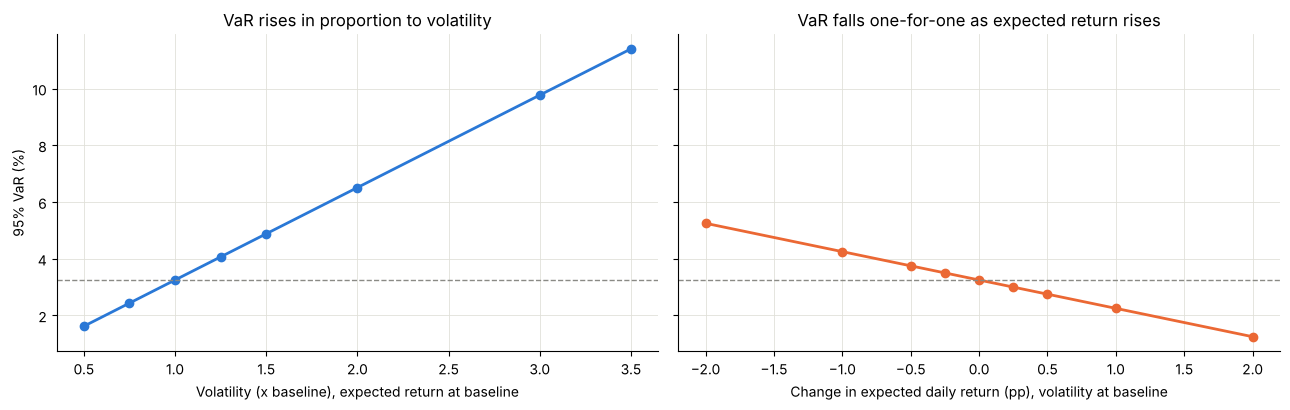

In [58]:
change = (grid - var_base) * 100
display(change.style.format("{:+.2f}").set_caption("Change in 95% VaR vs baseline (percentage points)"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
ax[0].plot(vol_mults, grid.loc["+0.00 pp"].values * 100, marker="o", color=C["hs"], lw=2)
ax[0].set_xlabel("Volatility (x baseline), expected return at baseline"); ax[0].set_ylabel("95% VaR (%)")
ax[0].set_title("VaR rises in proportion to volatility")
ax[1].plot(mu_shifts * 100, grid["1.00x"].values * 100, marker="o", color=C["ph"], lw=2)
ax[1].set_xlabel("Change in expected daily return (pp), volatility at baseline")
ax[1].set_title("VaR falls one-for-one as expected return rises")
for a in ax:
    a.axhline(var_base * 100, color="#8a8a85", ls="--", lw=1); a.grid(color="#e1e0d9", lw=0.6)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

#### 6.11 Historical reference points for the scenarios

To judge which scenarios are plausible, the table places some real 21-day periods of IndusInd Bank's history on the same axes: their average daily return relative to the baseline mean, their volatility relative to the baseline volatility, and the 95% VaR the formula gives with those inputs. It also lists the largest one-day losses since 2020.

In [59]:
m21 = returns.rolling(21).mean(); s21 = returns.rolling(21).std()
episodes = {
    "Calmest 21 days (lowest volatility)":        s21.idxmin(),
    "Most stressed 21 days (highest volatility)": s21.idxmax(),
    "Worst 21-day average return":                m21.idxmin(),
    "Best 21-day average return":                 m21.idxmax(),
    "Most recent 21 days":                        returns.index[-1],
}
anchors = pd.DataFrame({
    "21 days ending":         [d.date() for d in episodes.values()],
    "mean shift (pp/day)":    [(m21[d] - mu_base) * 100 for d in episodes.values()],
    "vol (x baseline)":       [s21[d] / sig_base for d in episodes.values()],
    "95% VaR with these inputs": [z95 * s21[d] - m21[d] for d in episodes.values()],
}, index=list(episodes.keys()))
display(anchors.style.format({"mean shift (pp/day)": "{:+.2f}", "vol (x baseline)": "{:.2f}x",
                              "95% VaR with these inputs": "{:.2%}"}))

worst = returns.nsmallest(5).to_frame("one-day return")
worst["loss / baseline 95% VaR"] = -worst["one-day return"] / var_base
worst.style.format({"one-day return": "{:.2%}", "loss / baseline 95% VaR": "{:.1f}x"})

,21 days ending,mean shift (pp/day),vol (x baseline),95% VaR with these inputs
Calmest 21 days (lowest volatility),2023-06-08,+0.55,0.34x,0.55%
Most stressed 21 days (highest volatility),2025-04-15,-0.71,3.41x,11.82%
Worst 21-day average return,2025-03-11,-2.14,3.05x,12.07%
Best 21-day average return,2020-12-01,+2.09,1.73x,3.55%
Most recent 21 days,2026-11-12,+0.43,1.09x,3.11%


,one-day return,loss / baseline 95% VaR
Date,,
2025-03-11 00:00:00,-27.16%,8.4x
2024-10-25 00:00:00,-18.63%,5.7x
2021-11-08 00:00:00,-10.76%,3.3x
2024-06-04 00:00:00,-9.03%,2.8x
2021-04-12 00:00:00,-8.58%,2.6x


#### 6.12 Key numbers for the discussion (auto-generated)

In [60]:
imax = np.unravel_index(np.argmax(grid.values), grid.shape)
imin = np.unravel_index(np.argmin(grid.values), grid.shape)
print(f"- Baseline 95% VaR = {var_base*100:.4f}% (matches Task 4).")
print(f"- Highest risk: {grid.index[imax[0]]} and {grid.columns[imax[1]]} volatility -> VaR = {grid.values[imax]*100:.2f}% "
      f"({grid.values[imax]/var_base:.1f}x baseline).")
print(f"- Lowest:       {grid.index[imin[0]]} and {grid.columns[imin[1]]} volatility -> VaR = {grid.values[imin]*100:.2f}%.")
print(f"- Volatility x2 (mean unchanged): {grid.loc['+0.00 pp','2.00x']*100:.2f}% | volatility x0.5: {grid.loc['+0.00 pp','0.50x']*100:.2f}%.")
print(f"- Mean -1 pp (volatility unchanged): {grid.loc['-1.00 pp','1.00x']*100:.2f}% | mean +1 pp: {grid.loc['+1.00 pp','1.00x']*100:.2f}%.")
neg = (grid < 0).sum().sum()
print(f"- Cells with negative VaR (expected gain larger than z*sigma): {neg} -> the formula then reports 'no loss at 95%', "
      "which shows how strongly an assumed positive drift can hide risk.")
print(f"- Largest one-day loss since 2020 = {-returns.min()*100:.1f}% ({returns.idxmin().date()}), "
      f"{-returns.min()/var_base:.1f}x the baseline 95% VaR.")

- Baseline 95% VaR = 3.2495% (matches Task 4).
- Highest risk: -2.00 pp and 3.50x volatility -> VaR = 13.40% (4.1x baseline).
- Lowest:       +2.00 pp and 0.50x volatility -> VaR = -0.38%.
- Volatility x2 (mean unchanged): 6.51% | volatility x0.5: 1.62%.
- Mean -1 pp (volatility unchanged): 4.25% | mean +1 pp: 2.25%.
- Cells with negative VaR (expected gain larger than z*sigma): 1 -> the formula then reports 'no loss at 95%', which shows how strongly an assumed positive drift can hide risk.
- Largest one-day loss since 2020 = 27.2% (2025-03-11), 8.4x the baseline 95% VaR.


In [61]:
# save tables for the report
comparison.to_csv("task6_var_comparison.csv")
grid.to_csv("task6_scenario_grid.csv")